In [1]:
#### FITTING THE MODELS WITHOUT BINNING AT ALL ####
# Every test so far computes a weighted median per Teff bin and fits four models to
# those bin values. That makes the answer depend on where the bin edges fall, which is
# the referee's concern, and it leaves only 8 to 37 points to fit -- few enough that
# AICc's small-sample term, 2k(k+1)/(n-k-1), charges the four-parameter model 9.3 in
# chi2 at eight bins but only 2.5 at thirty-seven. That fee is the same size as the
# effect being measured, so which model "wins" partly reflects how finely we binned.
#
# Quantile regression removes both problems. A weighted median is the value m that
# minimises sum(w * |R - m|), so fitting a curve through the median is just minimising
# sum(w * |R - f(Teff)|) over the curve's parameters -- the same estimator, with the
# bins taken out. Every planet enters individually, so there are no edges to place and
# n is fixed at 673 rather than chosen. At n=673 the AICc correction for k=4 is 0.06,
# which is the point: the model comparison stops depending on the binning.
#
# Two things to keep in mind about what this can and cannot settle. The loss is the
# check function at tau=0.5, so this tracks the median exactly as before, but turning
# it into an AICc needs a working likelihood (the asymmetric Laplace), and the radius
# distribution is not really Laplace. Differences in AICc here are therefore on a
# working scale and can be optimistic. That is precisely what the simulation in the
# later cells is for: it measures how often this procedure picks the right model when
# the truth is known, so the numbers printed below can be read with a calibration
# attached rather than taken at face value.

import glob
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

base = '.'
n_bootstrap = 1000

# Results of the long simulations are cached to disk so the plots below can be changed
# without paying for the fits again. The signature records everything a result depends on
# -- how many runs, the sample size, and the fitted parameters -- so editing any of those
# recomputes instead of silently reusing a stale file. Delete simulation_cache/ or set
# use_cache = False to force everything to rerun.
import pickle
from datetime import datetime

cache_dir = 'simulation_cache'
use_cache = True
os.makedirs(cache_dir, exist_ok=True)


def ladder_signature():
    return tuple(tuple(np.round(ladder[name]['params'], 8)) for name in models)


def cache_signature(*parts):
    return tuple(parts)


def load_cache(name, signature):
    path = os.path.join(cache_dir, name + '.pkl')
    if not use_cache or not os.path.exists(path):
        return None
    with open(path, 'rb') as f:
        stored = pickle.load(f)
    if stored['signature'] != signature:
        print(f"  cache for {name} does not match the current inputs, rerunning")
        return None
    print(f"  loaded {name} from cache, computed {stored['when']}")
    return stored['value']


def save_cache(name, signature, value):
    with open(os.path.join(cache_dir, name + '.pkl'), 'wb') as f:
        pickle.dump({'signature': signature, 'value': value,
                     'when': datetime.now().strftime('%Y-%m-%d %H:%M')}, f)
    return value



def load_completeness(directory):
    # One master heatmap CSV per Teff slice, stacked with the slice recorded per row
    completeness = pd.DataFrame()
    for f in sorted(glob.glob(os.path.join(directory, 'master_heatmap*.csv'))):
        match = re.search(r'(\d{4})_(\d{4})_K', os.path.basename(f))
        slice_df = pd.read_csv(f)
        slice_df['teff_bin'] = f"{match.group(1)}_{match.group(2)}"
        completeness = pd.concat([completeness, slice_df], ignore_index=True)
    return completeness


def log_edges(centers):
    centers = np.array(sorted(centers))
    logs = np.log10(centers)
    edges = [10 ** (logs[0] - (logs[1] - logs[0]) / 2)]
    for i in range(len(logs) - 1):
        edges.append(10 ** ((logs[i] + logs[i + 1]) / 2))
    edges.append(10 ** (logs[-1] + (logs[-1] - logs[-2]) / 2))
    return np.array(edges)


def cell_index(values, edges):
    inside = (values >= edges[0]) & (values < edges[-1])
    return np.where(inside, np.searchsorted(edges, values, side='right') - 1, np.nan)


completeness = load_completeness(base)
floored = completeness['detection_rate'] == 0
completeness.loc[floored, 'detection_rate'] = 1 / completeness.loc[floored, 'trials']
radius_edges = log_edges(completeness['radius_bin_center'].unique())
period_edges = log_edges(completeness['period_bin_center'].unique())
completeness['radius_cell'] = cell_index(completeness['radius_bin_center'].values, radius_edges)
completeness['period_cell'] = cell_index(completeness['period_bin_center'].values, period_edges)

planets = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv').dropna(subset=['st_teff', 'pl_rade'])
planets = planets[(planets['pl_rade'] > 1.8) & (planets['pl_rade'] < 4.0)]
planets = planets[(planets['pl_orbper'] > 0.6028) & (planets['pl_orbper'] < 25.1)]
planets = planets[planets['st_tmag'] < 13]
if 'tfopwg_disp' in planets.columns:
    planets = planets[planets['tfopwg_disp'] != 'FP']
planets = planets[['toi', 'st_teff', 'pl_rade', 'pl_orbper']].copy()

teff_bins = []
for teff_value in planets['st_teff']:
    found = np.nan
    for teff_min in range(3000, 7000, 500):
        if teff_min <= teff_value < teff_min + 500:
            found = f"{teff_min}_{teff_min + 500}"
    teff_bins.append(found)
planets['teff_bin'] = teff_bins
planets['radius_cell'] = cell_index(planets['pl_rade'].values, radius_edges)
planets['period_cell'] = cell_index(planets['pl_orbper'].values, period_edges)
planets = planets.merge(
    completeness[['teff_bin', 'radius_cell', 'period_cell', 'detection_rate', 'transit_prob']],
    on=['teff_bin', 'radius_cell', 'period_cell'], how='left')
planets['weight'] = (1 / planets['detection_rate'] * 1 / planets['transit_prob']).fillna(1)

teff = planets['st_teff'].values.astype(float)
radius = planets['pl_rade'].values.astype(float)
# Scaled so the weights average to one. Only their relative size matters to the fit,
# and this keeps the effective sample size equal to the number of planets actually
# observed rather than to the sum of the corrections, which would overstate the
# evidence by treating every represented planet as an independent measurement.
weights = planets['weight'].values.astype(float)
weights = weights / weights.mean()

x_min, x_max = teff.min(), teff.max()
n_planets = len(teff)
print(f"{n_planets} planets, Teff {x_min:.0f}-{x_max:.0f} K, "
      f"{int(planets['detection_rate'].notna().sum())} with a completeness cell")
print(f"Weights scaled to mean 1, range {weights.min():.3f}-{weights.max():.1f}")


def plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)


def slope(x, y0, s):
    return y0 + s * (np.asarray(x, dtype=float) - x_min)


def plateau_M(x, c, x1, s1):
    # Rises with slope s1 below x1, flat at c above it
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c + s1 * (x - x1), c)


def symmetric(x, c, x1, x2, s):
    # Rise, then flat between x1 and x2, then rise again with the same slope
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2)],
    )


models = {
    'Plateau': {'func': plateau, 'k': 1},
    'Slope': {'func': slope, 'k': 2},
    'Plateau+M': {'func': plateau_M, 'k': 3},
    'Symmetric': {'func': symmetric, 'k': 4},
}

model_labels = {
    'Plateau': 'Plateau',
    'Slope': 'Slope',
    'Plateau+M': 'Plateau with one sloping section',
    'Symmetric': 'Plateau with two sloping sections',
}


def check_loss(func, params, teff, radius, weights):
    # The tau=0.5 check function, whose minimiser is the weighted median
    return np.sum(weights * 0.5 * np.abs(radius - func(teff, *params)))


def starting_guesses(name, teff, radius):
    span = x_max - x_min
    level = np.median(radius)
    cool, hot = teff < np.median(teff), teff >= np.median(teff)
    gradient = (np.median(radius[hot]) - np.median(radius[cool])) / span
    if name == 'Plateau':
        return [[level]]
    if name == 'Slope':
        return [[level, gradient]]
    if name == 'Plateau+M':
        return [[level, x_min + f * span, gradient] for f in (0.2, 0.35, 0.5, 0.65, 0.8)]
    return [[level, x_min + a * span, x_min + b * span, gradient]
            for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55), (0.45, 0.85), (0.35, 0.6))]


def fit_model(name, teff, radius, weights):
    # The check loss is piecewise linear, so a gradient-free search is used, started
    # from several breakpoints because the surface is multi-modal in a breakpoint
    func = models[name]['func']
    best_loss, best_params = np.inf, None
    fallback_loss, fallback_params = np.inf, None
    for guess in starting_guesses(name, teff, radius):
        result = minimize(lambda p: check_loss(func, p, teff, radius, weights), guess,
                          method='Powell', options={'maxiter': 20000, 'xtol': 1e-4, 'ftol': 1e-6})
        params = np.array(result.x, dtype=float)
        if name in ('Plateau+M', 'Symmetric'):
            params[1] = np.clip(params[1], x_min, x_max)
            if name == 'Symmetric':
                params[2] = np.clip(params[2], x_min, x_max)
                if params[1] > params[2]:
                    # Crossed breakpoints are meaningless, but a run where every start
                    # crosses must still return something finite or the simulation below
                    # silently loses that sample. Keep the ordered version as a fallback.
                    ordered = params.copy()
                    ordered[1], ordered[2] = params[2], params[1]
                    ordered_loss = check_loss(func, ordered, teff, radius, weights)
                    if ordered_loss < fallback_loss:
                        fallback_loss, fallback_params = ordered_loss, ordered
                    continue
        loss = check_loss(func, params, teff, radius, weights)
        if not np.isfinite(loss):
            continue
        if loss < best_loss:
            best_loss, best_params = loss, params
    if best_params is None:
        return fallback_loss, fallback_params
    return best_loss, best_params


def fit_ladder(teff, radius, weights):
    # AICc from the asymmetric Laplace likelihood, whose MLE scale is the mean check
    # loss. Only differences between models matter, and every model shares the same n.
    n = len(teff)
    ladder = {}
    for name in models:
        loss, params = fit_model(name, teff, radius, weights)
        k = models[name]['k']
        sigma = loss / n
        log_likelihood = n * np.log(0.25) - n * np.log(sigma) - n
        aic = -2 * log_likelihood + 2 * k
        ladder[name] = {'k': k, 'loss': loss, 'params': params,
                        'AICc': aic + 2 * k * (k + 1) / (n - k - 1)}
    return ladder


ladder = fit_ladder(teff, radius, weights)
best_name = min(ladder, key=lambda name: ladder[name]['AICc'])
best_aicc = ladder[best_name]['AICc']

print(f"\nUnbinned quantile regression, all {n_planets} planets")
print("=" * 70)
print(f"{'Model':<12}{'k':>3}{'check loss':>13}{'AICc':>11}{'dAICc':>9}")
print("-" * 70)
for name, model in ladder.items():
    print(f"{name:<12}{model['k']:>3}{model['loss']:>13.3f}"
          f"{model['AICc']:>11.2f}{model['AICc'] - best_aicc:>9.2f}")
print(f"  Preferred by AICc: {best_name}")
print(f"  Plateau:    c={ladder['Plateau']['params'][0]:.3f}")
print(f"  Slope:      y0={ladder['Slope']['params'][0]:.3f}, "
      f"s={ladder['Slope']['params'][1]*1000:.4f} per 1000 K")
print(f"  Plateau+M:  c={ladder['Plateau+M']['params'][0]:.3f}, "
      f"x1={ladder['Plateau+M']['params'][1]:.0f} K, "
      f"s1={ladder['Plateau+M']['params'][2]*1000:.4f} per 1000 K")
print(f"  Symmetric:  c={ladder['Symmetric']['params'][0]:.3f}, "
      f"x1={ladder['Symmetric']['params'][1]:.0f} K, "
      f"x2={ladder['Symmetric']['params'][2]:.0f} K, "
      f"s={ladder['Symmetric']['params'][3]*1000:.4f} per 1000 K")
print(f"\n  AICc small-sample correction at n={n_planets}, k=4: "
      f"{2*4*5/(n_planets-5):.3f}  (it was 13.33 at eight bins)")

673 planets, Teff 3131-6920 K, 672 with a completeness cell
Weights scaled to mean 1, range 0.026-6.6

Unbinned quantile regression, all 673 planets
Model         k   check loss       AICc    dAICc
----------------------------------------------------------------------
Plateau       1      134.852    1050.18    49.02
Slope         2      132.171    1025.16    24.00
Plateau+M     3      130.648    1011.57    10.41
Symmetric     4      129.446    1001.16     0.00
  Preferred by AICc: Symmetric
  Plateau:    c=2.431
  Slope:      y0=2.208, s=0.1113 per 1000 K
  Plateau+M:  c=2.470, x1=4314 K, s1=0.4439 per 1000 K
  Symmetric:  c=2.462, x1=4227 K, x2=6108 K, s=0.4786 per 1000 K

  AICc small-sample correction at n=673, k=4: 0.060  (it was 13.33 at eight bins)


  loaded cell1_bootstrap from cache, computed 2026-09-30 17:07
Bootstrap over 500 resamples of the 673 planets
  Plateau+M  c         = 2.516 [2.449, 2.626]
             x1        = 4680 K [4251, 6745]
             s1        = 0.245 [0.118, 0.504] per 1000 K
  Symmetric  c         = 2.463 [2.431, 2.522]
             x1        = 4285 K [4176, 5136]
             x2        = 6101 K [5810, 6304]
             s         = 0.418 [0.133, 0.541] per 1000 K
  Plateau+M s1: 0.0% of resamples at or below zero
  Symmetric s: 0.4% of resamples at or below zero
  Breakpoint 68% widths: x1 spans 960 K, x2 spans 494 K


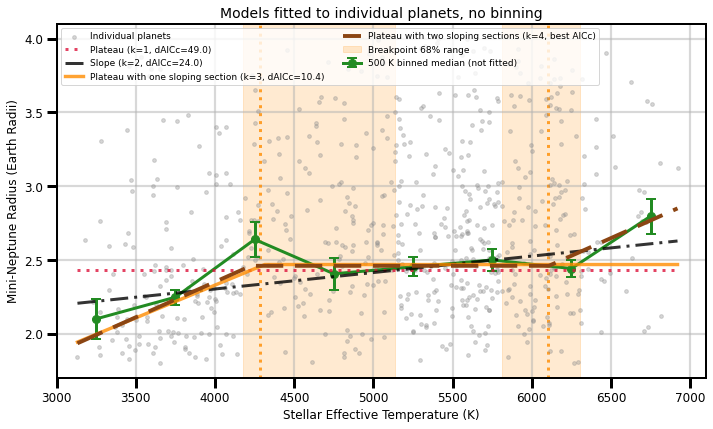

In [2]:
#### PARAMETER UNCERTAINTIES AND WHAT THE UNBINNED FIT LOOKS LIKE ####
# Resampling planets with replacement and refitting gives the spread on each parameter
# without any bin structure entering. The breakpoints are the interesting ones: if the
# cool-end break is real it should come back in a narrow range, and if the hot-end break
# is not, it should wander across whatever room the fit allows it.
#
# The binned medians are drawn underneath purely as a sanity check that the curve passes
# through the points the earlier notebooks were fitting. They take no part in the fit.

rng = np.random.default_rng(11)
n_bootstrap_params = 500

signature = cache_signature('cell1_bootstrap', n_bootstrap_params, n_planets, ladder_signature())
cached_result = load_cache('cell1_bootstrap', signature)
if cached_result is None:
    bootstrap = {'Plateau+M': [], 'Symmetric': []}
    for _ in range(n_bootstrap_params):
        pick = rng.integers(0, n_planets, size=n_planets)
        for name in bootstrap:
            loss, params = fit_model(name, teff[pick], radius[pick], weights[pick])
            if params is not None:
                bootstrap[name].append(params)

    for name in bootstrap:
        bootstrap[name] = np.array(bootstrap[name])
    save_cache('cell1_bootstrap', signature, bootstrap)
else:
    bootstrap = cached_result

print(f"Bootstrap over {n_bootstrap_params} resamples of the {n_planets} planets")
print("=" * 72)
one = bootstrap['Plateau+M']
print(f"  Plateau+M  c         = {np.median(one[:, 0]):.3f} "
      f"[{np.percentile(one[:, 0], 16):.3f}, {np.percentile(one[:, 0], 84):.3f}]")
print(f"             x1        = {np.median(one[:, 1]):.0f} K "
      f"[{np.percentile(one[:, 1], 16):.0f}, {np.percentile(one[:, 1], 84):.0f}]")
print(f"             s1        = {np.median(one[:, 2])*1000:.3f} "
      f"[{np.percentile(one[:, 2], 16)*1000:.3f}, {np.percentile(one[:, 2], 84)*1000:.3f}] per 1000 K")
two = bootstrap['Symmetric']
print(f"  Symmetric  c         = {np.median(two[:, 0]):.3f} "
      f"[{np.percentile(two[:, 0], 16):.3f}, {np.percentile(two[:, 0], 84):.3f}]")
print(f"             x1        = {np.median(two[:, 1]):.0f} K "
      f"[{np.percentile(two[:, 1], 16):.0f}, {np.percentile(two[:, 1], 84):.0f}]")
print(f"             x2        = {np.median(two[:, 2]):.0f} K "
      f"[{np.percentile(two[:, 2], 16):.0f}, {np.percentile(two[:, 2], 84):.0f}]")
print(f"             s         = {np.median(two[:, 3])*1000:.3f} "
      f"[{np.percentile(two[:, 3], 16)*1000:.3f}, {np.percentile(two[:, 3], 84)*1000:.3f}] per 1000 K")

# A slope consistent with zero would mean the sloping section is not needed at all
for name, column, what in [('Plateau+M', 2, 's1'), ('Symmetric', 3, 's')]:
    values = bootstrap[name][:, column]
    print(f"  {name} {what}: {100*np.mean(values <= 0):.1f}% of resamples at or below zero")
# How much of the grid the hot-end break explores, as a sign of whether it is pinned
span_x2 = np.percentile(two[:, 2], 84) - np.percentile(two[:, 2], 16)
span_x1 = np.percentile(two[:, 1], 84) - np.percentile(two[:, 1], 16)
print(f"  Breakpoint 68% widths: x1 spans {span_x1:.0f} K, x2 spans {span_x2:.0f} K")


def weighted_median(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    if keep.sum() == 0:
        return np.nan
    values, weights = values[keep], weights[keep]
    order = np.argsort(values)
    values, weights = values[order], weights[order]
    return float(values[np.searchsorted(np.cumsum(weights), 0.5 * weights.sum())])


def binned_medians(teff, radius, weights, edges, n_boot=300, seed=11):
    # The estimator the earlier notebooks use, kept here only for the overlay and for
    # the binned arm of the simulation below
    boot_rng = np.random.default_rng(seed)
    centers, medians, errors = [], [], []
    for i in range(len(edges) - 1):
        mask = (teff >= edges[i]) & (teff < edges[i + 1])
        if mask.sum() < 2:
            continue
        draws = []
        for _ in range(n_boot):
            pick = boot_rng.integers(0, int(mask.sum()), size=int(mask.sum()))
            draws.append(weighted_median(radius[mask][pick], weights[mask][pick]))
        error = np.nanstd(draws)
        if not np.isfinite(error) or error <= 1e-12:
            continue
        centers.append((edges[i] + edges[i + 1]) / 2)
        medians.append(weighted_median(radius[mask], weights[mask]))
        errors.append(error)
    return np.array(centers), np.array(medians), np.array(errors)


bins_500 = list(range(3000, 7001, 500))
bin_centers, bin_medians, bin_errors = binned_medians(teff, radius, weights, bins_500)

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Individual planet radii as grey transparent dots
ax.scatter(teff, radius, s=14, color='0.55', alpha=0.35, zorder=2, label='Individual planets')
ax.errorbar(bin_centers, bin_medians, yerr=bin_errors, color='forestgreen',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5, capthick=2,
            zorder=4, label='500 K binned median (not fitted)')

model_styles = {
    'Plateau': ('crimson', (0, (1, 2)), 3.0),
    'Slope': ('black', (0, (6, 2, 1, 2)), 3.0),
    'Plateau+M': ('darkorange', '-', 3.4),
    'Symmetric': ('saddlebrown', (0, (7, 3)), 2.4),
}
x_line = np.linspace(x_min, x_max, 600)
for name, (color, linestyle, linewidth) in model_styles.items():
    model = ladder[name]
    is_best = name == best_name
    if is_best:
        label = f"{model_labels[name]} (k={model['k']}, best AICc)"
    else:
        label = f"{model_labels[name]} (k={model['k']}, dAICc={model['AICc'] - best_aicc:.1f})"
    ax.plot(x_line, models[name]['func'](x_line, *model['params']), color=color, linestyle=linestyle,
            linewidth=linewidth + 1.5 if is_best else linewidth,
            alpha=1.0 if is_best else 0.8, zorder=5, label=label)

for value, name in ((np.median(two[:, 1]), 'Breakpoint 1'), (np.median(two[:, 2]), 'Breakpoint 2')):
    ax.axvline(value, color='darkorange', linestyle=':', linewidth=3, alpha=0.8, zorder=1)
ax.axvspan(np.percentile(two[:, 1], 16), np.percentile(two[:, 1], 84),
           color='darkorange', alpha=0.18, zorder=0, label='Breakpoint 68% range')
ax.axvspan(np.percentile(two[:, 2], 16), np.percentile(two[:, 2], 84),
           color='darkorange', alpha=0.18, zorder=0)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Mini-Neptune Radius (Earth Radii)', size=12)
ax.set_xlim(3000, 7100)
ax.set_ylim(1.7, 4.1)
ax.set_title('Models fitted to individual planets, no binning', size=14)
ax.legend(loc='upper left', fontsize=9, ncol=2)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_unbinned.png', dpi=300, bbox_inches='tight')

  loaded cell2_power from cache, computed 2026-09-30 17:11
Simulated 400 samples per truth, 673 planets each
truth                      Plateau    Slope   1 section   2 sections
------------------------------------------------------------------------------
one sloping section           1.5%    19.0%       60.5%        19.0%
two sloping sections          0.0%    39.0%       19.8%        41.2%

The quantity the paper leans on is dAICc(two sections - one section).
Observed in the real data: -10.41 (two sloping sections preferred)
------------------------------------------------------------------------------
  truth = one sloping section    median    +1.99, 68% range [-1.52, +2.29]
  truth = two sloping sections   median    +0.18, 68% range [-10.78, +3.17]
  P(dAICc <= observed | truth = one sloping section   ) = 0.062
  P(dAICc <= observed | truth = two sloping sections  ) = 0.168

  False positive rate (picks two when truth is one): 19.0%
  Power               (picks two when truth is tw

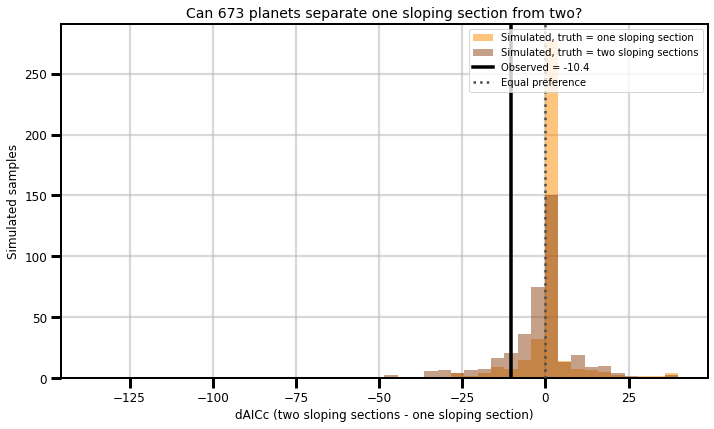

In [3]:
#### CAN THIS DATASET TELL ONE SLOPING SECTION FROM TWO? ####
# Every test so far has reported which model won without ever asking whether the data
# are capable of answering. This asks directly: build synthetic samples from a known
# truth, push them through the identical procedure, and count how often it recovers the
# model it was given.
#
# Each synthetic sample keeps the real Teff values and the real weights, so the sampling
# of stars and the corrections are exactly those of the actual survey. Only the radii
# are replaced: radius = truth(Teff) + residual, with residuals resampled from the real
# fit residuals so the scatter keeps its real shape and width rather than being assumed
# Gaussian.
#
# Two truths are run. Under "one sloping section" the procedure should rarely prefer two
# -- how often it does is the false-positive rate, and if that is high then a win for
# two sloping sections in the real data means very little. Under "two sloping sections"
# the fraction of times it recovers two is the power, and if that is low then a win for
# one sloping section means very little either. A procedure can easily fail both ways at
# once, which is the outcome worth knowing about before any of this goes in a paper.

n_simulations = 400
sim_rng = np.random.default_rng(11)

truths = {
    'one sloping section': ('Plateau+M', ladder['Plateau+M']['params']),
    'two sloping sections': ('Symmetric', ladder['Symmetric']['params']),
}

# Residuals about each truth, resampled to give the synthetic planets their scatter
residual_pool = {}
for label, (name, params) in truths.items():
    residual_pool[label] = radius - models[name]['func'](teff, *params)


def simulate(label):
    name, params = truths[label]
    draw = sim_rng.integers(0, n_planets, size=n_planets)
    return models[name]['func'](teff, *params) + residual_pool[label][draw]


signature = cache_signature('cell2_power', n_simulations, n_planets, ladder_signature())
cached_result = load_cache('cell2_power', signature)
if cached_result is None:
    results = {}
    for label in truths:
        picked = []
        delta_two_minus_one = []
        for _ in range(n_simulations):
            fake_radius = simulate(label)
            fake = fit_ladder(teff, fake_radius, weights)
            picked.append(min(fake, key=lambda m: fake[m]['AICc']))
            delta_two_minus_one.append(fake['Symmetric']['AICc'] - fake['Plateau+M']['AICc'])
        delta = np.array(delta_two_minus_one)
        dropped = int(np.sum(~np.isfinite(delta)))
        if dropped:
            print(f"  {label}: {dropped} of {n_simulations} samples dropped for a failed fit")
        results[label] = {'picked': picked, 'delta': delta[np.isfinite(delta)]}
    save_cache('cell2_power', signature, results)
else:
    results = cached_result

print(f"Simulated {n_simulations} samples per truth, {n_planets} planets each")
print("=" * 78)
print(f"{'truth':<24}{'Plateau':>10}{'Slope':>9}{'1 section':>12}{'2 sections':>13}")
print("-" * 78)
for label in truths:
    picked = results[label]['picked']
    counts = {name: picked.count(name) / n_simulations for name in models}
    print(f"{label:<24}{counts['Plateau']:>10.1%}{counts['Slope']:>9.1%}"
          f"{counts['Plateau+M']:>12.1%}{counts['Symmetric']:>13.1%}")

observed_delta = ladder['Symmetric']['AICc'] - ladder['Plateau+M']['AICc']
print(f"\nThe quantity the paper leans on is dAICc(two sections - one section).")
print(f"Observed in the real data: {observed_delta:+.2f} "
      f"({'two' if observed_delta < 0 else 'one'} sloping section{'s' if observed_delta < 0 else ''} preferred)")
print("-" * 78)
for label in truths:
    delta = results[label]['delta']
    print(f"  truth = {label:<22} median {np.median(delta):>+8.2f}, "
          f"68% range [{np.percentile(delta, 16):+.2f}, {np.percentile(delta, 84):+.2f}]")

# Where the observed value sits inside each simulated distribution is the calibration:
# if it is unremarkable under the one-section truth, it is not evidence against it
for label in truths:
    delta = results[label]['delta']
    print(f"  P(dAICc <= observed | truth = {label:<22}) = "
          f"{np.mean(delta <= observed_delta):.3f}")

false_positive = results['one sloping section']['picked'].count('Symmetric') / n_simulations
power = results['two sloping sections']['picked'].count('Symmetric') / n_simulations
print(f"\n  False positive rate (picks two when truth is one): {false_positive:.1%}")
print(f"  Power               (picks two when truth is two): {power:.1%}")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

edges = np.linspace(min(results[l]['delta'].min() for l in truths),
                    max(results[l]['delta'].max() for l in truths), 45)
for label, color in (('one sloping section', 'darkorange'), ('two sloping sections', 'saddlebrown')):
    ax.hist(results[label]['delta'], bins=edges, alpha=0.5, color=color,
            label=f'Simulated, truth = {label}')
ax.axvline(observed_delta, color='black', linewidth=3.5, zorder=5,
           label=f'Observed = {observed_delta:+.1f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=4,
           label='Equal preference')

ax.set_xlabel('dAICc (two sloping sections - one sloping section)', size=12)
ax.set_ylabel('Simulated samples', size=12)
ax.set_title(f'Can {n_planets} planets separate one sloping section from two?', size=14)
ax.legend(loc='upper right', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_power_unbinned.png', dpi=300, bbox_inches='tight')

  loaded cell3_binned from cache, computed 2026-09-30 17:11
Simulated 200 samples per truth, scored the 500 K binned way
truth                      Plateau    Slope   1 section   2 sections
------------------------------------------------------------------------------
one sloping section          26.5%    43.5%       30.0%         0.0%
two sloping sections         15.0%    60.0%       23.0%         2.0%

  False positive rate (picks two when truth is one): 0.0%
  Power               (picks two when truth is two): 2.0%

How often is the flat plateau correctly rejected?
  truth = one sloping section    flat picked 26.5% of the time
  truth = two sloping sections   flat picked 15.0% of the time

Unbinned against binned, same synthetic samples
------------------------------------------------------------
                            false positive     power
unbinned (n=673)                    19.0%     41.2%
500 K binned (n=8)                   0.0%      2.0%


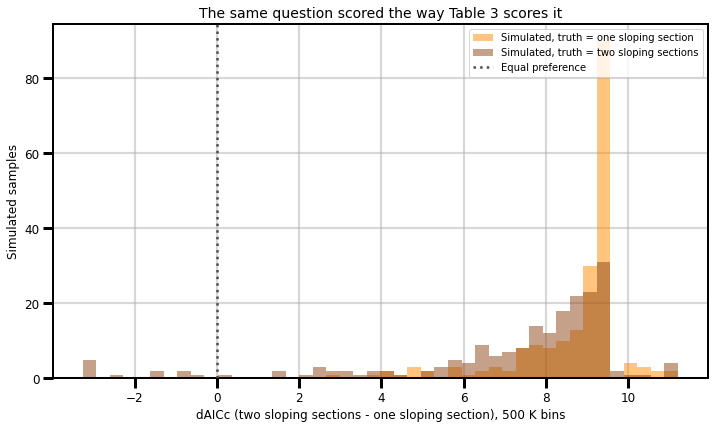

In [4]:
#### THE SAME QUESTION ASKED OF THE BINNED PROCEDURE IN THE PAPER ####
# The cell above calibrates the unbinned fit. Table 3 does not use the unbinned fit, so
# this repeats the exercise on the procedure the paper actually reports: 500 K bins,
# completeness-corrected weighted median per bin, bootstrap error bars, four models
# compared by AICc on eight points. The synthetic samples are generated exactly as
# before, so the only thing that changes between this cell and the last is the estimator.
#
# This is the number to quote if a referee asks what a dAICc of one or two in Table 3
# actually buys.

from scipy.optimize import curve_fit

n_simulations_binned = 200
binned_rng = np.random.default_rng(11)


def fit_ladder_binned(centers, medians, errors):
    # The curve_fit ladder used by the earlier notebooks, on bin values
    n_bins = len(medians)
    span = centers.max() - centers.min()
    level = np.median(medians)
    gradient = (medians[-1] - medians[0]) / span

    def slope_here(x, y0, s):
        return y0 + s * (np.asarray(x, dtype=float) - centers.min())

    setup = {
        'Plateau': (plateau, 1, [[level]], (-np.inf, np.inf)),
        'Slope': (slope_here, 2, [[medians[0], gradient]], (-np.inf, np.inf)),
        'Plateau+M': (plateau_M, 3,
                      [[level, centers.min() + f * span, gradient] for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
                      ([-np.inf, centers.min(), -np.inf], [np.inf, centers.max(), np.inf])),
        'Symmetric': (symmetric, 4,
                      [[level, centers.min() + a * span, centers.min() + b * span, gradient]
                       for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55), (0.45, 0.85), (0.35, 0.6))],
                      ([-np.inf, centers.min(), centers.min(), -np.inf],
                       [np.inf, centers.max(), centers.max(), np.inf])),
    }
    out = {}
    for name, (func, k, guess_list, bounds) in setup.items():
        best_chi2, best_params = np.inf, None
        for guess in guess_list:
            try:
                params, _ = curve_fit(func, centers, medians, p0=guess, sigma=errors,
                                      absolute_sigma=True, bounds=bounds, maxfev=40000)
            except Exception:
                continue
            if name == 'Symmetric' and params[1] > params[2]:
                continue
            chi2 = np.sum(((medians - func(centers, *params)) / errors) ** 2)
            if chi2 < best_chi2:
                best_chi2, best_params = chi2, params
        if best_params is None:
            return None
        out[name] = {'k': k, 'AICc': best_chi2 + 2 * k + 2 * k * (k + 1) / (n_bins - k - 1)}
    return out


signature = cache_signature('cell3_binned', n_simulations_binned, n_planets, ladder_signature())
cached_result = load_cache('cell3_binned', signature)
if cached_result is None:
    results_binned = {}
    for label in truths:
        picked = []
        delta_two_minus_one = []
        for i in range(n_simulations_binned):
            fake_radius = simulate(label)
            centers, medians, errors = binned_medians(teff, fake_radius, weights, bins_500,
                                                      n_boot=200, seed=int(binned_rng.integers(1e6)))
            if len(medians) < 6:
                continue
            fake = fit_ladder_binned(centers, medians, errors)
            if fake is None:
                continue
            picked.append(min(fake, key=lambda m: fake[m]['AICc']))
            delta_two_minus_one.append(fake['Symmetric']['AICc'] - fake['Plateau+M']['AICc'])
        delta = np.array(delta_two_minus_one)
        results_binned[label] = {'picked': picked, 'delta': delta[np.isfinite(delta)]}
    save_cache('cell3_binned', signature, results_binned)
else:
    results_binned = cached_result

print(f"Simulated {n_simulations_binned} samples per truth, scored the 500 K binned way")
print("=" * 78)
print(f"{'truth':<24}{'Plateau':>10}{'Slope':>9}{'1 section':>12}{'2 sections':>13}")
print("-" * 78)
for label in truths:
    picked = results_binned[label]['picked']
    total = len(picked)
    counts = {name: picked.count(name) / total for name in models}
    print(f"{label:<24}{counts['Plateau']:>10.1%}{counts['Slope']:>9.1%}"
          f"{counts['Plateau+M']:>12.1%}{counts['Symmetric']:>13.1%}")

false_positive_binned = (results_binned['one sloping section']['picked'].count('Symmetric')
                         / len(results_binned['one sloping section']['picked']))
power_binned = (results_binned['two sloping sections']['picked'].count('Symmetric')
                / len(results_binned['two sloping sections']['picked']))
print(f"\n  False positive rate (picks two when truth is one): {false_positive_binned:.1%}")
print(f"  Power               (picks two when truth is two): {power_binned:.1%}")

print("\nHow often is the flat plateau correctly rejected?")
for label in truths:
    picked = results_binned[label]['picked']
    print(f"  truth = {label:<22} flat picked {picked.count('Plateau')/len(picked):.1%} of the time")

print("\nUnbinned against binned, same synthetic samples")
print("-" * 60)
print(f"{'':<26}{'false positive':>16}{'power':>10}")
print(f"{'unbinned (n=673)':<26}{false_positive:>15.1%}{power:>10.1%}")
print(f"{'500 K binned (n=8)':<26}{false_positive_binned:>15.1%}{power_binned:>10.1%}")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

all_delta = np.concatenate([results_binned[l]['delta'] for l in truths])
edges = np.linspace(np.percentile(all_delta, 1), np.percentile(all_delta, 99), 45)
for label, color in (('one sloping section', 'darkorange'), ('two sloping sections', 'saddlebrown')):
    ax.hist(np.clip(results_binned[label]['delta'], edges[0], edges[-1]), bins=edges,
            alpha=0.5, color=color, label=f'Simulated, truth = {label}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=4, label='Equal preference')

ax.set_xlabel('dAICc (two sloping sections - one sloping section), 500 K bins', size=12)
ax.set_ylabel('Simulated samples', size=12)
ax.set_title('The same question scored the way Table 3 scores it', size=14)
ax.legend(loc='upper right', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_power_binned.png', dpi=300, bbox_inches='tight')

  loaded cell4_structure from cache, computed 2026-09-30 17:14
Simulated 400 samples per truth, unbinned, 673 planets each
truth                  Plateau    Slope   1 section   2 sections   any structure
----------------------------------------------------------------------------------
flat plateau             30.0%    23.0%       29.5%        17.5%           47.0%
straight line             1.0%    58.5%       26.8%        13.8%           40.5%

Gap = best structured AICc - best simple AICc. Negative means structure wins.
Observed in the real data: -24.00
----------------------------------------------------------------------------------
  truth = flat plateau     median    +0.35, 68% range [-6.20, +2.47], P(gap <= observed) = 0.0075
  truth = straight line    median    +0.59, 68% range [-3.81, +2.02], P(gap <= observed) = 0.0050

So the claim 'a plateau with a sloping section is needed' is supported at:
  p = 0.0075 against a flat plateau truth (calibrated by simulation)
  p = 0.0050 a

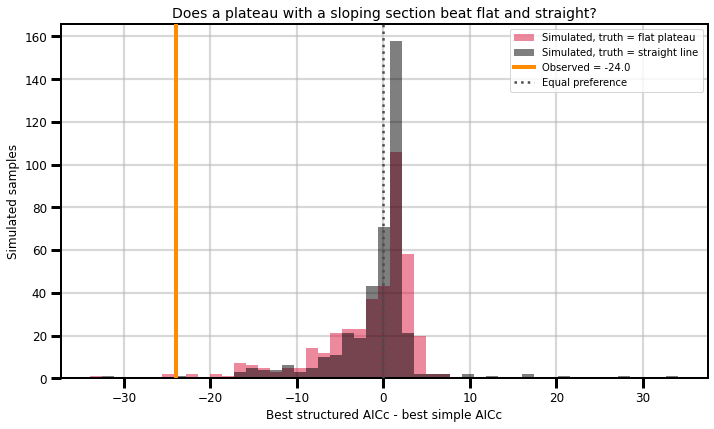

In [5]:
#### IS THE PLATEAU-PLUS-SLOPE SHAPE ITSELF NEEDED? ####
# The two cells above start from truths that already contain a plateau and a sloping
# section, so they answer "can we tell one sloping section from two" and nothing else.
# The claim that matters for the paper is the coarser one: that a plateau with a sloping
# section beats both a flat line and a straight line. Testing that needs the opposite
# simulation -- truths with no plateau structure at all -- to see how often the procedure
# manufactures one out of noise.
#
# A four-parameter model can always fit a straight line about as well as a two-parameter
# one, so the risk is real: if a straight-line truth frequently comes back preferring a
# plateau with slopes, then the real data doing so proves nothing.
#
# The quantity tracked is the gap between the best structured model (one or two sloping
# sections) and the best simple one (flat or straight). Negative means structure wins.

truths_simple = {
    'flat plateau': ('Plateau', ladder['Plateau']['params']),
    'straight line': ('Slope', ladder['Slope']['params']),
}
for label, (name, params) in truths_simple.items():
    residual_pool[label] = radius - models[name]['func'](teff, *params)
    truths[label] = (name, params)

structured = ('Plateau+M', 'Symmetric')
simple = ('Plateau', 'Slope')


def structure_gap(fitted):
    # Best structured model minus best simple one; negative means structure preferred
    return (min(fitted[m]['AICc'] for m in structured)
            - min(fitted[m]['AICc'] for m in simple))


observed_gap = structure_gap(ladder)

signature = cache_signature('cell4_structure', n_simulations, n_planets, ladder_signature())
cached_result = load_cache('cell4_structure', signature)
if cached_result is None:
    results_simple = {}
    for label in truths_simple:
        picked, gaps = [], []
        for _ in range(n_simulations):
            fake = fit_ladder(teff, simulate(label), weights)
            picked.append(min(fake, key=lambda m: fake[m]['AICc']))
            gaps.append(structure_gap(fake))
        gaps = np.array(gaps)
        results_simple[label] = {'picked': picked, 'gap': gaps[np.isfinite(gaps)]}
    save_cache('cell4_structure', signature, results_simple)
else:
    results_simple = cached_result

print(f"Simulated {n_simulations} samples per truth, unbinned, {n_planets} planets each")
print("=" * 82)
print(f"{'truth':<20}{'Plateau':>10}{'Slope':>9}{'1 section':>12}{'2 sections':>13}{'any structure':>16}")
print("-" * 82)
for label in truths_simple:
    picked = results_simple[label]['picked']
    counts = {name: picked.count(name) / n_simulations for name in models}
    any_structure = sum(picked.count(m) for m in structured) / n_simulations
    print(f"{label:<20}{counts['Plateau']:>10.1%}{counts['Slope']:>9.1%}"
          f"{counts['Plateau+M']:>12.1%}{counts['Symmetric']:>13.1%}{any_structure:>16.1%}")

print(f"\nGap = best structured AICc - best simple AICc. Negative means structure wins.")
print(f"Observed in the real data: {observed_gap:+.2f}")
print("-" * 82)
for label in truths_simple:
    gap = results_simple[label]['gap']
    print(f"  truth = {label:<16} median {np.median(gap):>+8.2f}, "
          f"68% range [{np.percentile(gap, 16):+.2f}, {np.percentile(gap, 84):+.2f}], "
          f"P(gap <= observed) = {np.mean(gap <= observed_gap):.4f}")

print("\nSo the claim 'a plateau with a sloping section is needed' is supported at:")
for label in truths_simple:
    p = np.mean(results_simple[label]['gap'] <= observed_gap)
    print(f"  p = {p:.4f} against a {label} truth "
          f"({'no simulation reached the observed gap' if p == 0 else 'calibrated by simulation'})")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

all_gap = np.concatenate([results_simple[l]['gap'] for l in truths_simple])
edges = np.linspace(min(all_gap.min(), observed_gap) - 1, all_gap.max() + 1, 50)
for label, color in (('flat plateau', 'crimson'), ('straight line', 'black')):
    ax.hist(results_simple[label]['gap'], bins=edges, alpha=0.5, color=color,
            label=f'Simulated, truth = {label}')
ax.axvline(observed_gap, color='darkorange', linewidth=4, zorder=5,
           label=f'Observed = {observed_gap:+.1f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=4, label='Equal preference')

ax.set_xlabel('Best structured AICc - best simple AICc', size=12)
ax.set_ylabel('Simulated samples', size=12)
ax.set_title('Does a plateau with a sloping section beat flat and straight?', size=14)
ax.legend(loc='upper right', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_power_structure.png', dpi=300, bbox_inches='tight')

  loaded cell5_figure from cache, computed 2026-09-30 17:21
  truth = flat plateau     6/1000 simulations reach the observed gap of -24.0  ->  p = 0.0060
  truth = straight line    4/1000 simulations reach the observed gap of -24.0  ->  p = 0.0040


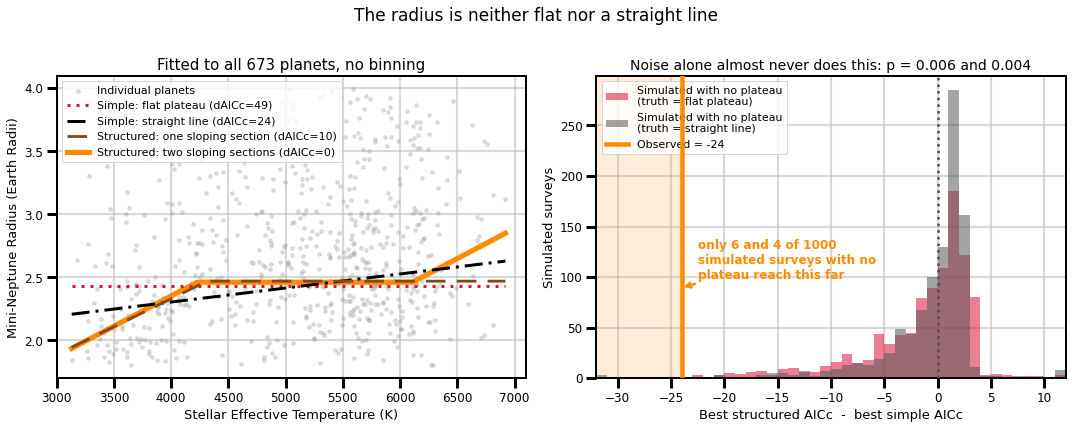

In [6]:
#### FIGURE FOR THE HEADLINE RESULT ####
# The cell above prints the numbers; this draws them, in the two halves the result
# actually has. Left is the fit itself: the three shapes laid over the planets they were
# fitted to, with no binning anywhere. Right is the calibration, which is the part that
# turns "the structured model won" into a claim worth making -- fake surveys built from
# truths containing no plateau at all, run through the identical procedure, against
# where the real data land.
#
# The simulation is rerun here rather than reusing the one above, at a higher count,
# because the answer lives in the tail. At 400 draws the smallest p expressible is
# 1/400 and the quoted value moved between 0.003 and 0.008 between runs; at 1000 it
# settles. That costs a few minutes -- drop n_figure_simulations back to 400 if that is
# too slow to sit through, since the picture is unchanged and only the third decimal of
# p moves.

n_figure_simulations = 1000
figure_rng = np.random.default_rng(11)

signature = cache_signature('cell5_figure', n_figure_simulations, n_planets, ladder_signature())
cached_result = load_cache('cell5_figure', signature)
if cached_result is None:
    figure_gaps = {}
    for label in truths_simple:
        name, params = truths_simple[label]
        truth_curve = models[name]['func'](teff, *params)
        gaps = []
        for _ in range(n_figure_simulations):
            draw = figure_rng.integers(0, n_planets, size=n_planets)
            fake = fit_ladder(teff, truth_curve + residual_pool[label][draw], weights)
            gaps.append(structure_gap(fake))
        gaps = np.array(gaps)
        figure_gaps[label] = gaps[np.isfinite(gaps)]
    save_cache('cell5_figure', signature, figure_gaps)
else:
    figure_gaps = cached_result

# Printed outside the loop above so the numbers still appear when the run is cached
for label in truths_simple:
    gaps = figure_gaps[label]
    reached = int(np.sum(gaps <= observed_gap))
    print(f"  truth = {label:<16} {reached}/{len(gaps)} simulations reach "
          f"the observed gap of {observed_gap:.1f}  ->  p = {reached/len(gaps):.4f}")


# Create the plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: the three shapes on the planets themselves
ax = axes[0]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Individual planet radii as grey transparent dots
ax.scatter(teff, radius, s=13, color='0.6', alpha=0.3, zorder=2, label='Individual planets')

# All four models, labelled by family, so the comparison on the right is legible as two
# against two rather than one shape against a vague alternative. The two structured
# models agree everywhere below 6100 K, so the thinner dashed one is drawn on top of the
# thicker one -- otherwise it vanishes underneath and only its hot-end stub shows.
shapes = [
    ('Plateau', 'crimson', (0, (1, 2)), 3.0, 5, 'Simple: flat plateau'),
    ('Slope', 'black', (0, (6, 2, 1, 2)), 3.0, 5, 'Simple: straight line'),
    ('Plateau+M', 'saddlebrown', (0, (7, 4)), 2.8, 6, 'Structured: one sloping section'),
    ('Symmetric', 'darkorange', '-', 5.2, 4, 'Structured: two sloping sections'),
]
x_line = np.linspace(x_min, x_max, 600)
for name, color, linestyle, linewidth, layer, label in shapes:
    delta = ladder[name]['AICc'] - min(ladder[m]['AICc'] for m in ladder)
    ax.plot(x_line, models[name]['func'](x_line, *ladder[name]['params']), color=color,
            linestyle=linestyle, linewidth=linewidth, zorder=layer,
            label=f'{label} (dAICc={delta:.0f})')

ax.set_xlabel('Stellar Effective Temperature (K)', size=13)
ax.set_ylabel('Mini-Neptune Radius (Earth Radii)', size=13)
ax.set_xlim(3000, 7100)
ax.set_ylim(1.7, 4.1)
ax.set_title(f'Fitted to all {n_planets} planets, no binning', size=15)
ax.legend(loc='upper left', fontsize=11)

# Right: how often noise with no plateau fakes a gap this large
ax = axes[1]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Outliers clipped into the end bins so the bulk stays readable rather than squashed
low, high = -32, 12
edges = np.linspace(low, high, 45)
for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35')):
    ax.hist(np.clip(figure_gaps[label], low, high), bins=edges, alpha=0.55, color=color,
            label=f'Simulated with no plateau\n(truth = {label})')

ax.axvspan(low, observed_gap, color='darkorange', alpha=0.15, zorder=0)
ax.axvline(observed_gap, color='darkorange', linewidth=4.5, zorder=6,
           label=f'Observed = {observed_gap:.0f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=4)

p_flat = np.mean(figure_gaps['flat plateau'] <= observed_gap)
p_line = np.mean(figure_gaps['straight line'] <= observed_gap)
top = ax.get_ylim()[1]
ax.annotate(f'only {int(np.sum(figure_gaps["flat plateau"] <= observed_gap))} and '
            f'{int(np.sum(figure_gaps["straight line"] <= observed_gap))} of {n_figure_simulations}\n'
            f'simulated surveys with no\nplateau reach this far',
            xy=(observed_gap, top * 0.30), xytext=(observed_gap + 1.5, top * 0.33),
            fontsize=12, color='darkorange', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='darkorange', linewidth=2.5))

ax.set_xlabel('Best structured AICc  -  best simple AICc', size=13)
ax.set_ylabel('Simulated surveys', size=13)
ax.set_xlim(low, high)
ax.set_title(f'Noise alone almost never does this: p = {p_flat:.3f} and {p_line:.3f}', size=14)
ax.legend(loc='upper left', fontsize=11)

for ax in axes:
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

fig.suptitle('The radius is neither flat nor a straight line', size=17)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

fig.savefig('statistical_analysis_teff_result1.png', dpi=300, bbox_inches='tight')

  loaded cell6_power from cache, computed 2026-09-30 17:26
Threshold for a 5% test, set by the no-plateau runs: -13.76
Observed in the real data: -24.00
truth                      median gap   clears threshold   false negative
------------------------------------------------------------------------------
flat plateau                    +0.09              5.0%  (false positive)
straight line                   +0.79              2.3%  (false positive)
one sloping section             -7.81             34.6%            65.4%
two sloping sections            -3.10             26.4%            73.6%

How often is structure not preferred at all, even loosely (gap > 0)?
  truth = one sloping section    20.2%
  truth = two sloping sections   40.6%


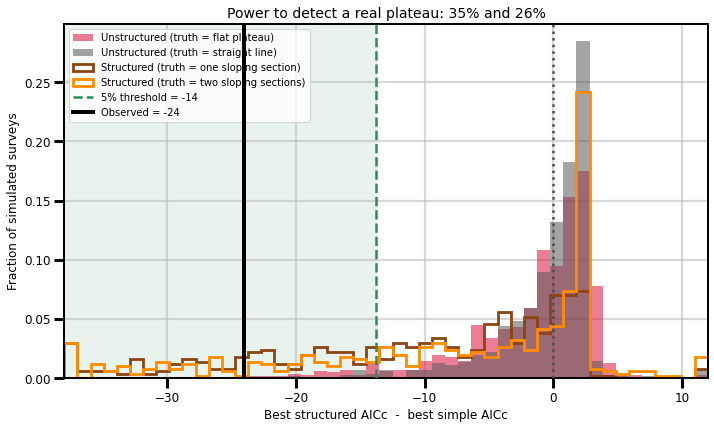

In [7]:
#### HOW OFTEN WOULD A REAL PLATEAU BE MISSED? ####
# The cell above asks how often noise fakes the result. This asks the other half: when a
# plateau with a sloping section really is there, how often does this procedure fail to
# find it. Without that number the p-value is only half a calibration -- a test can be
# very hard to fool and still be blind.
#
# A false negative rate needs a threshold, and the observed -24 is not one: that is just
# where this particular survey landed, and asking "how often does a real plateau reach
# -24" measures the size of the effect, not the sensitivity of the test. The threshold
# used here is the 5th percentile of the no-plateau runs -- the value that a no-plateau
# survey beats only 5% of the time. The more negative of the two nulls is taken so the
# test is honest against both. Power is then the fraction of real-plateau surveys that
# clear it, and the false negative rate is what is left over.
#
# The two no-plateau distributions are reused from the cell above rather than resimulated,
# so the threshold and the p-values refer to exactly the same runs.

n_power_simulations = 500
power_rng = np.random.default_rng(11)

no_plateau = ['flat plateau', 'straight line']
has_plateau = ['one sloping section', 'two sloping sections']

signature = cache_signature('cell6_power', n_power_simulations, n_planets, ladder_signature())
cached_result = load_cache('cell6_power', signature)
if cached_result is None:
    power_gaps = {}
    for label in has_plateau:
        name, params = truths[label]
        truth_curve = models[name]['func'](teff, *params)
        gaps = []
        for _ in range(n_power_simulations):
            draw = power_rng.integers(0, n_planets, size=n_planets)
            fake = fit_ladder(teff, truth_curve + residual_pool[label][draw], weights)
            gaps.append(structure_gap(fake))
        gaps = np.array(gaps)
        power_gaps[label] = gaps[np.isfinite(gaps)]
    save_cache('cell6_power', signature, power_gaps)
else:
    power_gaps = cached_result

# The 5% threshold, taken from whichever null reaches further left
threshold = min(np.percentile(figure_gaps[label], 5) for label in no_plateau)

print(f"Threshold for a 5% test, set by the no-plateau runs: {threshold:+.2f}")
print(f"Observed in the real data: {observed_gap:+.2f}")
print("=" * 78)
print(f"{'truth':<24}{'median gap':>13}{'clears threshold':>19}{'false negative':>17}")
print("-" * 78)
for label in no_plateau:
    gaps = figure_gaps[label]
    print(f"{label:<24}{np.median(gaps):>+13.2f}{np.mean(gaps <= threshold):>18.1%}"
          f"{'  (false positive)':>17}")
for label in has_plateau:
    gaps = power_gaps[label]
    power = np.mean(gaps <= threshold)
    print(f"{label:<24}{np.median(gaps):>+13.2f}{power:>18.1%}{1 - power:>17.1%}")

print("\nHow often is structure not preferred at all, even loosely (gap > 0)?")
for label in has_plateau:
    print(f"  truth = {label:<22} {np.mean(power_gaps[label] > 0):.1%}")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

everything = np.concatenate([figure_gaps[l] for l in no_plateau]
                            + [power_gaps[l] for l in has_plateau])
low, high = np.floor(np.percentile(everything, 1)), 12
edges = np.linspace(low, high, 50)

# No-plateau truths filled, real-plateau truths outlined, so the two families separate
for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35')):
    gaps = figure_gaps[label]
    ax.hist(np.clip(gaps, low, high), bins=edges, alpha=0.55, color=color,
            weights=np.full(len(gaps), 1 / len(gaps)),
            label=f'Unstructured (truth = {label})')
for label, color in (('one sloping section', 'saddlebrown'), ('two sloping sections', 'darkorange')):
    gaps = power_gaps[label]
    ax.hist(np.clip(gaps, low, high), bins=edges, histtype='step', linewidth=2.8, color=color,
            weights=np.full(len(gaps), 1 / len(gaps)),
            label=f'Structured (truth = {label})')

ax.axvspan(low, threshold, color='seagreen', alpha=0.10, zorder=0)
ax.axvline(threshold, color='seagreen', linestyle='--', linewidth=2.5, zorder=4,
           label=f'5% threshold = {threshold:.0f}')
ax.axvline(observed_gap, color='black', linewidth=4, zorder=6,
           label=f'Observed = {observed_gap:.0f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=3)

power_one = np.mean(power_gaps['one sloping section'] <= threshold)
power_two = np.mean(power_gaps['two sloping sections'] <= threshold)
ax.set_xlabel('Best structured AICc  -  best simple AICc', size=12)
ax.set_ylabel('Fraction of simulated surveys', size=12)
ax.set_xlim(low, high)
ax.set_title(f'Power to detect a real plateau: {power_one:.0%} and {power_two:.0%}', size=14)
ax.legend(loc='upper left', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_false_negative.png', dpi=300, bbox_inches='tight')

  one sloping section    removed a constant offset of +0.1856 R_Earth
  two sloping sections   removed a constant offset of +0.1623 R_Earth
  flat plateau           removed a constant offset of +0.1797 R_Earth
  straight line          removed a constant offset of +0.1870 R_Earth

Binned weighted medians of 1000 generated surveys per truth
bin (K)         observed               one               two              flat          straight
------------------------------------------------------------------------------------
3000-3500          2.101    1.88-2.22         1.88-2.22         2.25-2.61         2.05-2.42     
3500-4000          2.250    2.14-2.33         2.16-2.36         2.33-2.56         2.17-2.36     
4000-4500          2.638    2.30-2.52         2.32-2.55         2.31-2.56         2.21-2.42     
4500-5000          2.405    2.37-2.56         2.37-2.57         2.32-2.54         2.28-2.48     
5000-5500          2.453    2.39-2.55         2.39-2.56         2.34-2.53         2.35-2.

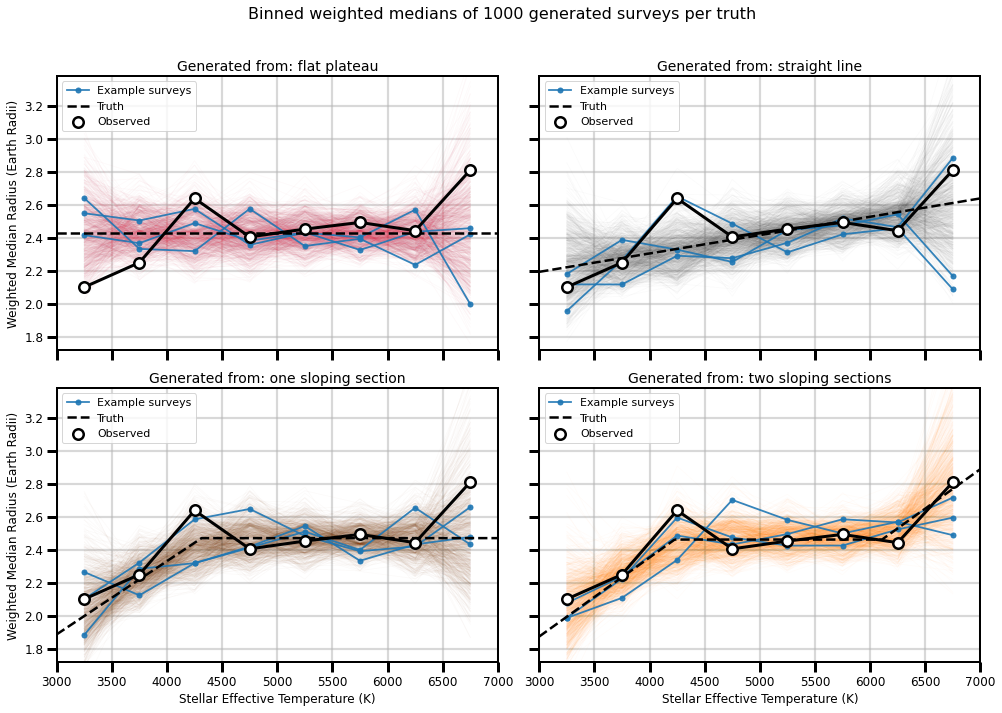

In [8]:
#### WHAT DO THE GENERATED SAMPLES ACTUALLY LOOK LIKE? ####
# Every cell above reports a number that came out of the simulated samples without ever
# showing the samples themselves. This draws them: for each of the four truths, 1000
# generated surveys reduced to their binned weighted medians, one thin line each, with
# the truth and the real survey on top.
#
# The point of comparison is the real data. If the black points sit inside the spread of
# a truth's lines, that truth generates surveys like the one observed. If they sit
# outside it, the generating scheme is not reproducing the real survey, and any power or
# false-negative number resting on that truth needs treating with suspicion.
#
# No model fitting happens here, only binned weighted medians, so this is fast.
#
# One correction is applied before generating. The residual pool has weighted median zero
# -- that is what the fit enforces -- but the resampling draw is uniform over planets, so
# what actually gets added is the pool's UNWEIGHTED centre, about +0.18 R_Earth. Left
# alone, every generated survey sits that far above the real one and the panels show
# nothing but a constant gap. It is a pure offset: identical for all four truths, at
# every Teff, and absorbed by the free level parameter every model has, so removing it
# changes none of the AICc gaps or p-values in the cells above. It is subtracted here so
# the comparison is about shape, which is the thing actually in question.

# Cells 2 and 4 put truths and residual_pool in the namespace, but reaching them costs
# about eight minutes of simulation that nothing here needs. The dictionaries themselves
# are instant to rebuild from the fitted ladder, so on a fresh kernel this cell rebuilds
# them and cell 0 followed by this cell is enough -- about fifteen seconds in total.
if 'residual_pool' not in globals():
    truths = {
        'one sloping section': ('Plateau+M', ladder['Plateau+M']['params']),
        'two sloping sections': ('Symmetric', ladder['Symmetric']['params']),
        'flat plateau': ('Plateau', ladder['Plateau']['params']),
        'straight line': ('Slope', ladder['Slope']['params']),
    }
    residual_pool = {}
    for label in truths:
        name, params = truths[label]
        residual_pool[label] = radius - models[name]['func'](teff, *params)
    print("Rebuilt truths and residual_pool: cells 2 and 4 were not run in this kernel\n")

n_median_simulations = 1000
median_rng = np.random.default_rng(11)

median_bins = np.array([3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000])
bin_centers = 0.5 * (median_bins[:-1] + median_bins[1:])


def weighted_median(values, w):
    order = np.argsort(values)
    values, w = values[order], w[order]
    cumulative = np.cumsum(w) - 0.5 * w
    return np.interp(0.5 * np.sum(w), cumulative, values)


def binned_weighted_medians(sample_radius):
    # Weighted median in each Teff bin, nan where the bin is too thin to mean anything
    medians = []
    for i in range(len(median_bins) - 1):
        bin_mask = (teff >= median_bins[i]) & (teff < median_bins[i + 1])
        if bin_mask.sum() < 2:
            medians.append(np.nan)
        else:
            medians.append(weighted_median(sample_radius[bin_mask], weights[bin_mask]))
    return np.array(medians)


observed_medians = binned_weighted_medians(radius)

simulated_medians = {}
for label in truths:
    name, params = truths[label]
    truth_curve = models[name]['func'](teff, *params)
    centred_pool = residual_pool[label] - np.median(residual_pool[label])
    print(f"  {label:<22} removed a constant offset of "
          f"{np.median(residual_pool[label]):+.4f} R_Earth")
    lines = []
    for _ in range(n_median_simulations):
        draw = median_rng.integers(0, n_planets, size=n_planets)
        lines.append(binned_weighted_medians(truth_curve + centred_pool[draw]))
    simulated_medians[label] = np.array(lines)
print()

print(f"Binned weighted medians of {n_median_simulations} generated surveys per truth")
print("=" * 84)
print(f"{'bin (K)':<14}{'observed':>10}", end='')
for label in truths:
    print(f"{label.split()[0][:8]:>18}", end='')
print()
print("-" * 84)
for i in range(len(bin_centers)):
    print(f"{median_bins[i]}-{median_bins[i+1]:<9}{observed_medians[i]:>10.3f}", end='')
    for label in truths:
        column = simulated_medians[label][:, i]
        column = column[np.isfinite(column)]
        print(f"{np.percentile(column, 16):>8.2f}-{np.percentile(column, 84):<9.2f}", end='')
    print()
print("\nEach pair is the 16th-84th percentile of the generated surveys in that bin.")

# Where the real survey sits inside each truth's spread, bin by bin
print("\nPercentile of the observed median within each truth's simulated spread")
print("-" * 84)
for label in truths:
    places = []
    for i in range(len(bin_centers)):
        column = simulated_medians[label][:, i]
        column = column[np.isfinite(column)]
        places.append(100 * np.mean(column <= observed_medians[i]))
    outside = sum(1 for p in places if p < 2.5 or p > 97.5)
    print(f"  {label:<22}" + "".join(f"{p:>6.0f}" for p in places)
          + f"   ({outside} of {len(places)} bins outside 2.5-97.5%)")


# Create the plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

panels = [
    ('flat plateau', 'crimson'),
    ('straight line', '0.35'),
    ('one sloping section', 'saddlebrown'),
    ('two sloping sections', 'darkorange'),
]
x_line = np.linspace(median_bins[0], median_bins[-1], 400)
for ax, (label, color) in zip(axes.flat, panels):
    ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    # Every generated survey as one faint line
    for line in simulated_medians[label]:
        ax.plot(bin_centers, line, color=color, alpha=0.025, linewidth=0.8, zorder=2)

    # Three of them drawn solid. A thousand faint lines show the envelope but not what a
    # single simulated survey looks like, and the answer matters: each one is an eight
    # point track with its own kinks, as jagged as the observed one.
    for j in range(3):
        ax.plot(bin_centers, simulated_medians[label][j], color='tab:blue', linewidth=1.8,
                alpha=0.9, marker='o', markersize=5, zorder=3,
                label='Example surveys' if j == 0 else None)

    # The truth the surveys were generated from
    name, params = truths[label]
    ax.plot(x_line, models[name]['func'](x_line, *params), color='black', linestyle='--',
            linewidth=2.5, zorder=4, label='Truth')

    # The real survey
    ax.plot(bin_centers, observed_medians, color='black', linewidth=3, zorder=5)
    ax.scatter(bin_centers, observed_medians, s=110, facecolor='white', edgecolor='black',
               linewidth=2.5, zorder=6, label='Observed')

    ax.set_title(f'Generated from: {label}', size=14)
    ax.legend(loc='upper left', fontsize=11)
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

spread = np.concatenate([simulated_medians[l].ravel() for l in truths])
spread = spread[np.isfinite(spread)]
axes[0, 0].set_ylim(np.percentile(spread, 0.2) - 0.05, np.percentile(spread, 99.8) + 0.05)
axes[0, 0].set_xlim(median_bins[0], median_bins[-1])
for ax in axes[1, :]:
    ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
for ax in axes[:, 0]:
    ax.set_ylabel('Weighted Median Radius (Earth Radii)', size=12)

fig.suptitle(f'Binned weighted medians of {n_median_simulations} generated surveys per truth', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

fig.savefig('statistical_analysis_teff_generated_medians.png', dpi=300, bbox_inches='tight')

  loaded cell8_criteria from cache, computed 2026-10-01 05:12
Observed gap: AIC -24.04,  AICc -24.00,  BIC -15.02
Every truth simulated 1000 times, one denominator throughout
truth                          AIC reach obs      AICc reach obs       BIC reach obs
--------------------------------------------------------------------------------------
one sloping section          147/1000  0.147     147/1000  0.147     199/1000  0.199
two sloping sections         134/1000  0.134     134/1000  0.134     147/1000  0.147
flat plateau                   6/1000  0.006       6/1000  0.006       5/1000  0.005
straight line                  7/1000  0.007       7/1000  0.007       7/1000  0.007

Power at a 5% threshold set by the no-plateau runs, per criterion
--------------------------------------------------------------------------------------
  AIC    threshold  -12.64   power  36.5% (one section),  29.9% (two sections)
  AICc   threshold  -12.61   power  36.6% (one section),  29.9% (two sections)
 

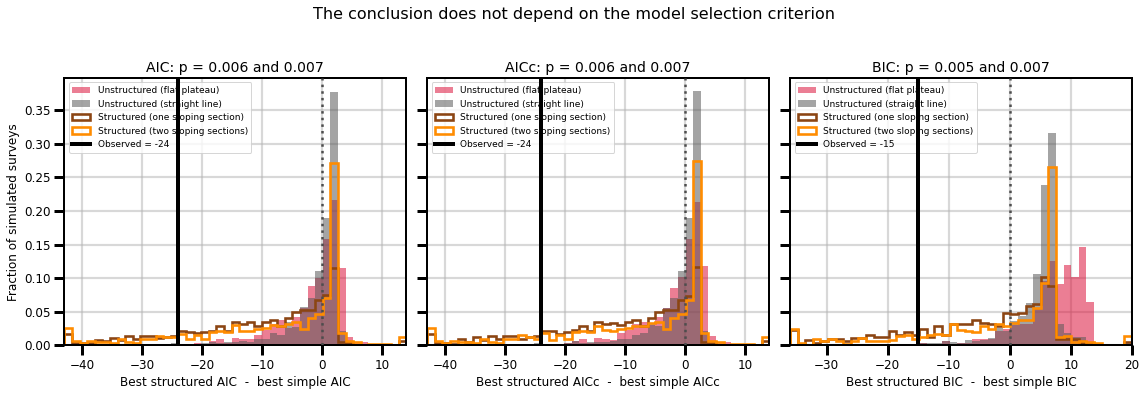

In [9]:
#### DOES THE ANSWER DEPEND ON AICc, AIC OR BIC? ####
# Two questions get settled here. First, how often a survey generated from a real plateau
# reaches the observed gap -- the same "X in 1000" the no-plateau runs give, so all four
# truths are quoted from one denominator. Second, whether any of it depends on the model
# selection criterion.
#
# The worry about the criterion is reasonable: unbinned, the dAICc values are far larger
# than the binned ones, and the AICc correction that dominated the eight-point fits is
# 2k(k+1)/(n-k-1) = 0.06 at n=673, so it does nothing. What remains is the penalty itself,
# 2k for AIC and k*log(n) = 6.51k for BIC, and BIC charges three times as much per
# parameter. If the preference for a structured model were an artefact of a lenient
# penalty, BIC would overturn it.
#
# It should not matter, and it is worth being explicit about why. The p-value never reads
# the criterion against a fixed scale like "a gap of 10 is decisive". The criterion is
# only a test statistic -- one number computed the same way for the real survey and for
# every simulated one -- and the p-value is the fraction of simulations reaching the real
# value. Change the criterion and both sides change together. What can genuinely shift is
# the power, since a harsher penalty makes structure harder to prefer at all.
#
# That is also the answer to the degrees of freedom question. The correct effective
# number of parameters for a fit with an unidentified breakpoint and a working likelihood
# is genuinely unclear, and nothing here needs it. The simulation derives the
# distribution of the statistic empirically instead of assuming one, so whatever the
# right penalty would have been, the real survey and the simulated ones are all scored
# with the same wrong one and the p-value comes out unaffected.
#
# For scale on why the criterion mattered so much before and so little now: the AICc
# correction charged 9.33 at the eight binned points behind Table 3, comparable to the
# effect being measured, which is why AICc was necessary there and why AIC values cannot
# be compared across fits with different n. At n=673 the same term is 0.06.
#
# All three criteria are derived from the same fits. Only the penalty differs, so this
# costs one simulation pass rather than three.

n_criterion_simulations = 1000
criterion_rng = np.random.default_rng(11)

# Rebuild what cells 2 and 4 provide, so this cell runs straight after cell 0
if 'residual_pool' not in globals():
    truths = {
        'one sloping section': ('Plateau+M', ladder['Plateau+M']['params']),
        'two sloping sections': ('Symmetric', ladder['Symmetric']['params']),
        'flat plateau': ('Plateau', ladder['Plateau']['params']),
        'straight line': ('Slope', ladder['Slope']['params']),
    }
    residual_pool = {}
    for label in truths:
        name, params = truths[label]
        residual_pool[label] = radius - models[name]['func'](teff, *params)
    print("Rebuilt truths and residual_pool: cells 2 and 4 were not run in this kernel\n")

structured = ('Plateau+M', 'Symmetric')
simple = ('Plateau', 'Slope')
criteria = ['AIC', 'AICc', 'BIC']


def criterion_value(loss, k, n, criterion):
    # Same working likelihood the ladder uses; only the penalty changes
    sigma = loss / n
    log_likelihood = n * np.log(0.25) - n * np.log(sigma) - n
    if criterion == 'AIC':
        return -2 * log_likelihood + 2 * k
    if criterion == 'AICc':
        return -2 * log_likelihood + 2 * k + 2 * k * (k + 1) / (n - k - 1)
    return -2 * log_likelihood + k * np.log(n)


def gap_under(fitted, criterion):
    value = {}
    for name in fitted:
        value[name] = criterion_value(fitted[name]['loss'], fitted[name]['k'],
                                      n_planets, criterion)
    return min(value[m] for m in structured) - min(value[m] for m in simple)


observed = {}
for criterion in criteria:
    observed[criterion] = gap_under(ladder, criterion)

signature = cache_signature('cell8_criteria', n_criterion_simulations, n_planets, ladder_signature())
cached_result = load_cache('cell8_criteria', signature)
if cached_result is None:
    criterion_gaps = {}
    for label in truths:
        name, params = truths[label]
        truth_curve = models[name]['func'](teff, *params)
        collected = {criterion: [] for criterion in criteria}
        for _ in range(n_criterion_simulations):
            draw = criterion_rng.integers(0, n_planets, size=n_planets)
            fake = fit_ladder(teff, truth_curve + residual_pool[label][draw], weights)
            for criterion in criteria:
                collected[criterion].append(gap_under(fake, criterion))
        for criterion in criteria:
            gaps = np.array(collected[criterion])
            criterion_gaps[(label, criterion)] = gaps[np.isfinite(gaps)]
    save_cache('cell8_criteria', signature, criterion_gaps)
else:
    criterion_gaps = cached_result

print(f"Observed gap: " + ",  ".join(f"{c} {observed[c]:+.2f}" for c in criteria))
print(f"Every truth simulated {n_criterion_simulations} times, one denominator throughout")
print("=" * 86)
print(f"{'truth':<24}" + "".join(f"{c + ' reach obs':>20}" for c in criteria))
print("-" * 86)
for label in truths:
    print(f"{label:<24}", end='')
    for criterion in criteria:
        gaps = criterion_gaps[(label, criterion)]
        reached = int(np.sum(gaps <= observed[criterion]))
        print(f"{reached:>8}/{len(gaps):<5}{reached / len(gaps):>6.3f}", end='')
    print()

print("\nPower at a 5% threshold set by the no-plateau runs, per criterion")
print("-" * 86)
no_plateau = ['flat plateau', 'straight line']
has_plateau = ['one sloping section', 'two sloping sections']
for criterion in criteria:
    threshold = min(np.percentile(criterion_gaps[(l, criterion)], 5) for l in no_plateau)
    powers = []
    for label in has_plateau:
        powers.append(np.mean(criterion_gaps[(label, criterion)] <= threshold))
    print(f"  {criterion:<6} threshold {threshold:>+7.2f}   "
          f"power {powers[0]:>6.1%} (one section), {powers[1]:>6.1%} (two sections)")

print("\nMedian gap by truth and criterion")
print("-" * 86)
for label in truths:
    print(f"  {label:<24}"
          + "".join(f"{criterion} {np.median(criterion_gaps[(label, criterion)]):>+8.2f}   "
                    for criterion in criteria))


# Create the plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)

for ax, criterion in zip(axes, criteria):
    ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    everything = np.concatenate([criterion_gaps[(l, criterion)] for l in truths])
    low, high = np.floor(np.percentile(everything, 1)), np.ceil(np.percentile(everything, 99.5))
    edges = np.linspace(low, high, 46)
    for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35')):
        gaps = criterion_gaps[(label, criterion)]
        ax.hist(np.clip(gaps, low, high), bins=edges, alpha=0.55, color=color,
                weights=np.full(len(gaps), 1 / len(gaps)),
                label=f'Unstructured ({label})')
    for label, color in (('one sloping section', 'saddlebrown'),
                         ('two sloping sections', 'darkorange')):
        gaps = criterion_gaps[(label, criterion)]
        ax.hist(np.clip(gaps, low, high), bins=edges, histtype='step', linewidth=2.6,
                color=color, weights=np.full(len(gaps), 1 / len(gaps)),
                label=f'Structured ({label})')

    ax.axvline(observed[criterion], color='black', linewidth=4, zorder=6,
               label=f'Observed = {observed[criterion]:.0f}')
    ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=3)

    reached_flat = np.mean(criterion_gaps[('flat plateau', criterion)] <= observed[criterion])
    reached_line = np.mean(criterion_gaps[('straight line', criterion)] <= observed[criterion])
    ax.set_xlim(low, high)
    ax.set_xlabel(f'Best structured {criterion}  -  best simple {criterion}', size=12)
    ax.set_title(f'{criterion}: p = {reached_flat:.3f} and {reached_line:.3f}', size=14)
    ax.legend(loc='upper left', fontsize=9)
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

axes[0].set_ylabel('Fraction of simulated surveys', size=12)
fig.suptitle('The conclusion does not depend on the model selection criterion', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

fig.savefig('statistical_analysis_teff_criteria.png', dpi=300, bbox_inches='tight')

  loaded cell9_ratio_forward from cache, computed 2026-10-19 15:42
Likelihood ratio statistic, D = 2N ln(loss ratio)
Surveys generated by the forward model, detection simulated
Observed in the real data: D = -28.04
truth                       median D    reach observed         p
------------------------------------------------------------------------------
one sloping section            -9.29           43/1000    0.0430
two sloping sections          -11.18          108/1000    0.1080
flat plateau                   -3.87            7/1000    0.0070
straight line                  -1.98            2/1000    0.0020

5% threshold from the no-plateau runs: D = -18.65
  power against one sloping section     17.7%   false negative  82.3%
  power against two sloping sections    28.8%   false negative  71.2%

Fraction of surveys where the structured models fit better (D < 0):
  truth = one sloping section    97.9%
  truth = two sloping sections   92.4%
  truth = flat plateau           89.7%
  tr

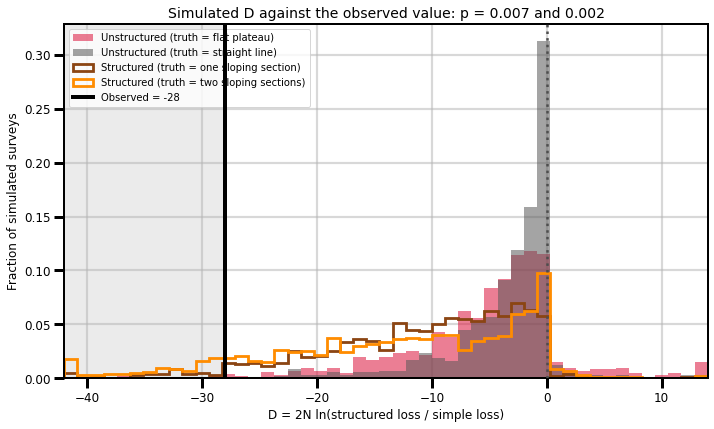

In [10]:
#### THE SAME TEST WITH NO MODEL SELECTION PENALTY AT ALL ####
# The cell above showed the answer survives AIC, AICc and BIC. This removes the penalty
# entirely, which is the cleanest form of the argument: a likelihood ratio statistic with
# a simulated null distribution instead of the asymptotic chi-squared one.
#
# The statistic is the plain improvement in fit from allowing the structured models,
# D = 2n log(loss_structured / loss_simple), with nothing subtracted for the extra
# parameters. On its own it is uninformative, because the structured models nest the
# simple ones and so always fit at least as well -- D is negative for essentially every
# survey, real or simulated. What carries the information is how negative it is compared
# to surveys built with no structure in them, where the extra parameters are buying
# nothing real. That pile of simulations IS the complexity correction, measured for this
# model, this sample size and this Teff coverage, rather than taken from a formula.
#
# Why the formula is worth avoiding here: the chi-squared reference a likelihood ratio
# test would normally use needs every parameter identified under the null, and the
# breakpoint is not -- if the truth is flat, the breakpoint can sit anywhere and the fit
# is unchanged. The working likelihood is an asymmetric Laplace rather than the true one,
# and the weights break the information matrix equality on top of that. Any one of those
# is enough to sink the asymptotics. The simulation needs none of them.
#
# The surveys are generated by the forward model used throughout, with detection
# simulated and the weights re-read at each planet's new radius.
#
# Note what the statistic reduces to. With no penalty the best structured model is always
# Symmetric and the best simple one is always Slope, since each nests the other members
# of its family. So this is a clean four parameter against two parameter nested
# comparison, and the last block checks that dAIC for that fixed pair is exactly D plus a
# constant -- which is why the penalty never mattered.

n_ratio_simulations = 1000
ratio_rng = np.random.default_rng(11)

if 'residual_pool' not in globals():
    truths = {
        'one sloping section': ('Plateau+M', ladder['Plateau+M']['params']),
        'two sloping sections': ('Symmetric', ladder['Symmetric']['params']),
        'flat plateau': ('Plateau', ladder['Plateau']['params']),
        'straight line': ('Slope', ladder['Slope']['params']),
    }
    residual_pool = {}
    for label in truths:
        name, params = truths[label]
        residual_pool[label] = radius - models[name]['func'](teff, *params)
    print("Rebuilt truths and residual_pool: cells 2 and 4 were not run in this kernel\n")

structured = ('Plateau+M', 'Symmetric')
simple = ('Plateau', 'Slope')
no_plateau = ['flat plateau', 'straight line']
has_plateau = ['one sloping section', 'two sloping sections']


def likelihood_ratio(fitted):
    # Twice the log likelihood improvement, no penalty. Negative means structure fits better.
    best_structured = min(fitted[m]['loss'] for m in structured)
    best_simple = min(fitted[m]['loss'] for m in simple)
    return 2 * n_planets * np.log(best_structured / best_simple)


def fixed_pair(fitted):
    # The same thing for one nominated pair, so the constant offset argument can be checked
    return 2 * n_planets * np.log(fitted['Symmetric']['loss'] / fitted['Slope']['loss'])


# This cell runs before the forward model is set up, so the generator is rebuilt here.
# Only the lookup is needed, not the simulations those cells carry, so it costs a second.
if 'build_draw_probabilities' not in globals():
    grid_weight = {}
    for row in completeness.itertuples():
        if np.isfinite(row.radius_cell) and np.isfinite(row.period_cell):
            grid_weight[(row.teff_bin, int(row.radius_cell), int(row.period_cell))] = (
                1 / row.detection_rate * 1 / row.transit_prob)

    radius_cells = sorted(int(c) for c in completeness['radius_cell'].dropna().unique())
    weight_table = np.full((n_planets, max(radius_cells) + 1), np.nan)
    for i, planet in enumerate(planets.itertuples()):
        if not np.isfinite(planet.period_cell):
            continue
        for cell in radius_cells:
            found = grid_weight.get((planet.teff_bin, cell, int(planet.period_cell)))
            if found is not None:
                weight_table[i, cell] = found

    raw_weights = planets['weight'].values.astype(float)
    raw_mean = raw_weights.mean()

    def weights_for(sample_radius):
        cells = cell_index(sample_radius, radius_edges)
        found = np.full(n_planets, np.nan)
        inside = np.isfinite(cells)
        rows = np.arange(n_planets)[inside]
        found[inside] = weight_table[rows, cells[inside].astype(int)]
        found = np.where(np.isfinite(found), found, 1.0)
        return found / raw_mean

    def build_draw_probabilities(truth_curve):
        candidates = truth_curve[:, None] + residual_pool_here[None, :]
        cells = cell_index(candidates.ravel(), radius_edges).reshape(candidates.shape)
        detectability = np.zeros_like(candidates)
        inside = np.isfinite(cells)
        rows = np.repeat(np.arange(n_planets), n_planets).reshape(candidates.shape)
        grid = weight_table[rows[inside], cells[inside].astype(int)]
        detectability[inside] = np.where(np.isfinite(grid), 1.0 / grid, 0.0)
        probability = detectability * raw_weights[None, :]
        total = probability.sum(axis=1, keepdims=True)
        dead = (total[:, 0] == 0)
        probability[dead] = 1.0
        total[dead] = n_planets
        return np.cumsum(probability / total, axis=1)


observed_ratio = likelihood_ratio(ladder)
observed_pair = fixed_pair(ladder)

signature = cache_signature('cell9_ratio_forward', n_ratio_simulations, n_planets,
                            ladder_signature())
cached_result = load_cache('cell9_ratio_forward', signature)
if cached_result is None:
    ratio_gaps = {}
    pair_gaps = {}
    for label in truths:
        name, params = truths[label]
        truth_curve = models[name]['func'](teff, *params)
        residual_pool_here = residual_pool[label]
        cumulative = build_draw_probabilities(truth_curve)
        collected, pairs = [], []
        for _ in range(n_ratio_simulations):
            u = ratio_rng.random(n_planets)
            picked = (cumulative < u[:, None]).sum(axis=1).clip(0, n_planets - 1)
            fake_radius = truth_curve + residual_pool_here[picked]
            fake = fit_ladder(teff, fake_radius, weights_for(fake_radius))
            collected.append(likelihood_ratio(fake))
            pairs.append(fixed_pair(fake))
        collected, pairs = np.array(collected), np.array(pairs)
        ratio_gaps[label] = collected[np.isfinite(collected)]
        pair_gaps[label] = pairs[np.isfinite(pairs)]
    save_cache('cell9_ratio_forward', signature, (ratio_gaps, pair_gaps))
else:
    ratio_gaps, pair_gaps = cached_result

print(f"Likelihood ratio statistic, D = 2N ln(loss ratio)")
print(f"Surveys generated by the forward model, detection simulated")
print(f"Observed in the real data: D = {observed_ratio:+.2f}")
print("=" * 78)
print(f"{'truth':<24}{'median D':>12}{'reach observed':>18}{'p':>10}")
print("-" * 78)
for label in truths:
    gaps = ratio_gaps[label]
    reached = int(np.sum(gaps <= observed_ratio))
    print(f"{label:<24}{np.median(gaps):>+12.2f}{f'{reached}/{len(gaps)}':>18}"
          f"{reached / len(gaps):>10.4f}")

threshold = min(np.percentile(ratio_gaps[label], 5) for label in no_plateau)
print(f"\n5% threshold from the no-plateau runs: D = {threshold:+.2f}")
for label in has_plateau:
    power = np.mean(ratio_gaps[label] <= threshold)
    print(f"  power against {label:<22} {power:>6.1%}   false negative {1 - power:>6.1%}")

# Every simulated survey prefers the structured model on raw fit, which is the point:
# the statistic means nothing until it is compared with the no-structure runs
print("\nFraction of surveys where the structured models fit better (D < 0):")
for label in truths:
    print(f"  truth = {label:<22} {np.mean(ratio_gaps[label] < 0):.1%}")

print("\nCheck: for the fixed pair Symmetric (k=4) against Slope (k=2),")
print("dAIC is exactly D plus a constant, so the p-value cannot change.")
print("-" * 78)
offset = 2 * (models['Symmetric']['k'] - models['Slope']['k'])
print(f"  constant = 2*(4-2) = {offset}")
for label in no_plateau:
    from_d = np.mean(pair_gaps[label] <= observed_pair)
    from_aic = np.mean(pair_gaps[label] + offset <= observed_pair + offset)
    print(f"  truth = {label:<16} p from D = {from_d:.4f}, "
          f"p from dAIC = {from_aic:.4f}  {'match' if from_d == from_aic else 'DIFFER'}")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

everything = np.concatenate([ratio_gaps[l] for l in truths])
low, high = np.floor(np.percentile(everything, 0.5)), np.ceil(np.percentile(everything, 99.5))
edges = np.linspace(low, high, 50)
for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35')):
    gaps = ratio_gaps[label]
    ax.hist(np.clip(gaps, low, high), bins=edges, alpha=0.55, color=color,
            weights=np.full(len(gaps), 1 / len(gaps)),
            label=f'Unstructured (truth = {label})')
for label, color in (('one sloping section', 'saddlebrown'), ('two sloping sections', 'darkorange')):
    gaps = ratio_gaps[label]
    ax.hist(np.clip(gaps, low, high), bins=edges, histtype='step', linewidth=2.8, color=color,
            weights=np.full(len(gaps), 1 / len(gaps)),
            label=f'Structured (truth = {label})')

ax.axvspan(low, observed_ratio, color='black', alpha=0.08, zorder=0)
ax.axvline(observed_ratio, color='black', linewidth=4, zorder=6,
           label=f'Observed = {observed_ratio:.0f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=3)

p_flat = np.mean(ratio_gaps['flat plateau'] <= observed_ratio)
p_line = np.mean(ratio_gaps['straight line'] <= observed_ratio)
ax.set_xlabel('D = 2N ln(structured loss / simple loss)', size=12)
ax.set_ylabel('Fraction of simulated surveys', size=12)
ax.set_xlim(low, high)
ax.set_title(f'Simulated D against the observed value: p = {p_flat:.3f} and {p_line:.3f}', size=14)
ax.legend(loc='upper left', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_no_penalty.png', dpi=300, bbox_inches='tight')

Rebuilt weights at the real radii match cell 0: True  (max difference 0.00e+00)
Real planets outside the 1.8-4.0 R_Earth selection: 0.0%
  loaded cell10_weights from cache, computed 2026-10-01 12:24

Observed gap (unchanged, the real planets keep their real weights): -24.00
truth                     runs  median frozen  median correct   p frozen   p correct
------------------------------------------------------------------------------------------
one sloping section        300          -7.92           -3.81     0.1500      0.0200
two sloping sections       300          -2.76           -6.55     0.1500      0.0567
flat plateau              1000          +0.20           +1.18     0.0060      0.0000
straight line             1000          +0.85           -0.52     0.0060      0.0030

How far apart are the two gaps within the same simulated survey?
------------------------------------------------------------------------------------------
  one sloping section    median   +5.28, 68% range [

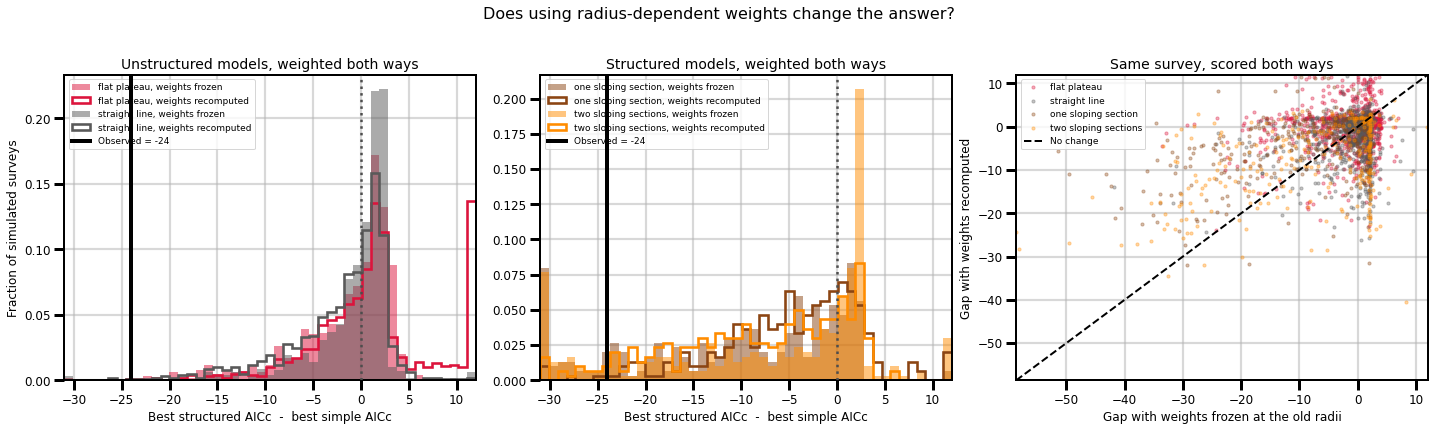

In [11]:
#### DOES IT MATTER THAT THE WEIGHTS BELONG TO THE OLD RADII? ####
# Every simulation so far gives a fake planet a new radius but leaves it carrying its
# original weight. That weight is not a property of the planet, it is a property of the
# grid cell the planet sits in: weight = 1/detection_rate * 1/transit_prob, looked up by
# (Teff slice, radius cell, period cell). Change the radius and the cell changes, so both
# factors change -- a smaller planet is harder to detect and also transits less often.
#
# So a fake planet moved from 2.1 to 2.9 R_Earth is being corrected as though it were
# still the hard-to-find 2.1, which over-weights it. The bias is not random either: the
# generated radii are pushed around a fitted curve, so whole stretches of Teff can be
# systematically mis-weighted.
#
# This cell redoes the simulation both ways. Teff and period never change, so each
# planet's Teff slice and period cell are fixed and only the radius cell moves; the
# correct weight is the grid value at (that planet's Teff slice, its NEW radius cell, its
# period cell). Everything else is identical, so any difference is the weighting alone.

n_weight_simulations = 1000
n_weight_simulations_structured = 300
weight_rng = np.random.default_rng(11)

if 'residual_pool' not in globals():
    truths = {
        'one sloping section': ('Plateau+M', ladder['Plateau+M']['params']),
        'two sloping sections': ('Symmetric', ladder['Symmetric']['params']),
        'flat plateau': ('Plateau', ladder['Plateau']['params']),
        'straight line': ('Slope', ladder['Slope']['params']),
    }
    residual_pool = {}
    for label in truths:
        name, params = truths[label]
        residual_pool[label] = radius - models[name]['func'](teff, *params)
    print("Rebuilt truths and residual_pool: cells 2 and 4 were not run in this kernel\n")

structured = ('Plateau+M', 'Symmetric')
simple = ('Plateau', 'Slope')
no_plateau = ['flat plateau', 'straight line']
has_plateau = ['one sloping section', 'two sloping sections']


def aicc_gap(fitted):
    return (min(fitted[m]['AICc'] for m in structured)
            - min(fitted[m]['AICc'] for m in simple))


# A lookup of grid weight for every planet at every radius cell it could land in. Teff
# slice and period cell stay fixed, so this is the whole space the radius can move over.
grid_weight = {}
for row in completeness.itertuples():
    if np.isfinite(row.radius_cell) and np.isfinite(row.period_cell):
        grid_weight[(row.teff_bin, int(row.radius_cell), int(row.period_cell))] = (
            1 / row.detection_rate * 1 / row.transit_prob)

radius_cells = sorted(int(c) for c in completeness['radius_cell'].dropna().unique())
weight_table = np.full((n_planets, max(radius_cells) + 1), np.nan)
for i, planet in enumerate(planets.itertuples()):
    if not np.isfinite(planet.period_cell):
        continue
    for cell in radius_cells:
        found = grid_weight.get((planet.teff_bin, cell, int(planet.period_cell)))
        if found is not None:
            weight_table[i, cell] = found

raw_mean = planets['weight'].values.astype(float).mean()


def weights_for(sample_radius):
    # The grid weight at each planet's new radius cell, scaled the same way as cell 0
    cells = cell_index(sample_radius, radius_edges)
    found = np.full(n_planets, np.nan)
    inside = np.isfinite(cells)
    rows = np.arange(n_planets)[inside]
    found[inside] = weight_table[rows, cells[inside].astype(int)]
    found = np.where(np.isfinite(found), found, 1.0)
    return found / raw_mean


# Sanity check: at the real radii this must reproduce the weights cell 0 built
rebuilt = weights_for(radius)
print(f"Rebuilt weights at the real radii match cell 0: "
      f"{np.allclose(rebuilt, weights)}  "
      f"(max difference {np.max(np.abs(rebuilt - weights)):.2e})")

outside = np.mean((radius < 1.8) | (radius > 4.0))
print(f"Real planets outside the 1.8-4.0 R_Earth selection: {outside:.1%}")


signature = cache_signature('cell10_weights', n_weight_simulations, n_weight_simulations_structured, n_planets, ladder_signature())
cached_result = load_cache('cell10_weights', signature)
if cached_result is None:
    results = {}
    for label in truths:
        name, params = truths[label]
        truth_curve = models[name]['func'](teff, *params)
        runs = n_weight_simulations if label in no_plateau else n_weight_simulations_structured
        frozen_gaps, correct_gaps, escaped = [], [], []
        for _ in range(runs):
            draw = weight_rng.integers(0, n_planets, size=n_planets)
            fake_radius = truth_curve + residual_pool[label][draw]
            frozen_gaps.append(aicc_gap(fit_ladder(teff, fake_radius, weights)))
            correct_gaps.append(aicc_gap(fit_ladder(teff, fake_radius, weights_for(fake_radius))))
            escaped.append(np.mean((fake_radius < 1.8) | (fake_radius > 4.0)))
        frozen_gaps, correct_gaps = np.array(frozen_gaps), np.array(correct_gaps)
        good = np.isfinite(frozen_gaps) & np.isfinite(correct_gaps)
        results[label] = {'frozen': frozen_gaps[good], 'correct': correct_gaps[good],
                          'escaped': float(np.mean(escaped)), 'runs': runs}
    save_cache('cell10_weights', signature, results)
else:
    results = cached_result

observed_gap_here = aicc_gap(ladder)
print(f"\nObserved gap (unchanged, the real planets keep their real weights): "
      f"{observed_gap_here:+.2f}")
print("=" * 90)
print(f"{'truth':<24}{'runs':>6}{'median frozen':>15}{'median correct':>16}"
      f"{'p frozen':>11}{'p correct':>12}")
print("-" * 90)
for label in truths:
    r = results[label]
    p_frozen = np.mean(r['frozen'] <= observed_gap_here)
    p_correct = np.mean(r['correct'] <= observed_gap_here)
    print(f"{label:<24}{r['runs']:>6}{np.median(r['frozen']):>+15.2f}"
          f"{np.median(r['correct']):>+16.2f}{p_frozen:>11.4f}{p_correct:>12.4f}")

print("\nHow far apart are the two gaps within the same simulated survey?")
print("-" * 90)
for label in truths:
    r = results[label]
    difference = r['correct'] - r['frozen']
    print(f"  {label:<22} median {np.median(difference):>+7.2f}, "
          f"68% range [{np.percentile(difference, 16):+.2f}, {np.percentile(difference, 84):+.2f}], "
          f"|diff| > 2 in {np.mean(np.abs(difference) > 2):.1%}")

print("\nFake planets pushed outside the 1.8-4.0 R_Earth selection window")
print("-" * 90)
for label in truths:
    print(f"  {label:<22} {results[label]['escaped']:.1%} of generated planets")


# Create the plot
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
everything = np.concatenate([results[l][k] for l in truths for k in ('frozen', 'correct')])
low, high = np.floor(np.percentile(everything, 1)), 12
edges = np.linspace(low, high, 48)
for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35')):
    ax.hist(np.clip(results[label]['frozen'], low, high), bins=edges, alpha=0.5, color=color,
            weights=np.full(len(results[label]['frozen']), 1 / len(results[label]['frozen'])),
            label=f'{label}, weights frozen')
    ax.hist(np.clip(results[label]['correct'], low, high), bins=edges, histtype='step',
            linewidth=2.6, color=color,
            weights=np.full(len(results[label]['correct']), 1 / len(results[label]['correct'])),
            label=f'{label}, weights recomputed')
ax.axvline(observed_gap_here, color='black', linewidth=4, zorder=6,
           label=f'Observed = {observed_gap_here:.0f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=3)
ax.set_xlabel('Best structured AICc  -  best simple AICc', size=12)
ax.set_ylabel('Fraction of simulated surveys', size=12)
ax.set_xlim(low, high)
ax.set_title('Unstructured models, weighted both ways', size=14)
ax.legend(loc='upper left', fontsize=9)

# The truths that actually contain a plateau, where the weighting moves things most --
# their radii differ from the real ones at every Teff, so planets really do change cells
ax = axes[1]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
for label, color in (('one sloping section', 'saddlebrown'), ('two sloping sections', 'darkorange')):
    ax.hist(np.clip(results[label]['frozen'], low, high), bins=edges, alpha=0.5, color=color,
            weights=np.full(len(results[label]['frozen']), 1 / len(results[label]['frozen'])),
            label=f'{label}, weights frozen')
    ax.hist(np.clip(results[label]['correct'], low, high), bins=edges, histtype='step',
            linewidth=2.6, color=color,
            weights=np.full(len(results[label]['correct']), 1 / len(results[label]['correct'])),
            label=f'{label}, weights recomputed')
ax.axvline(observed_gap_here, color='black', linewidth=4, zorder=6,
           label=f'Observed = {observed_gap_here:.0f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=3)
ax.set_xlabel('Best structured AICc  -  best simple AICc', size=12)
ax.set_xlim(low, high)
ax.set_title('Structured models, weighted both ways', size=14)
ax.legend(loc='upper left', fontsize=9)

ax = axes[2]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35'),
                     ('one sloping section', 'saddlebrown'), ('two sloping sections', 'darkorange')):
    ax.scatter(results[label]['frozen'], results[label]['correct'], s=10, alpha=0.35,
               color=color, label=label)
limits = [min(everything.min(), -40), 12]
ax.plot(limits, limits, color='black', linestyle='--', linewidth=2, zorder=5,
        label='No change')
ax.set_xlabel('Gap with weights frozen at the old radii', size=12)
ax.set_ylabel('Gap with weights recomputed', size=12)
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_title('Same survey, scored both ways', size=14)
ax.legend(loc='upper left', fontsize=9)

for ax in axes:
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

fig.suptitle('Does using radius-dependent weights change the answer?', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

fig.savefig('statistical_analysis_teff_weight_check.png', dpi=300, bbox_inches='tight')

  loaded cell11_forward from cache, computed 2026-10-01 12:33
Validation of the forward model
  Real planets:   median radius 2.610, 16-84% 2.13-3.37 R_Earth
  one sloping section    median radius 2.542, 16-84% 2.15-3.23
  two sloping sections   median radius 2.539, 16-84% 2.17-3.22
  flat plateau           median radius 2.564, 16-84% 2.14-3.28
  straight line          median radius 2.543, 16-84% 2.14-3.25

  The observed residuals sit +0.162 above the fitted curve, unweighted.
  Detection should reproduce that offset without it being put in by hand:
    one sloping section    generated offset +0.132 R_Earth
    two sloping sections   generated offset +0.116 R_Earth
    flat plateau           generated offset +0.124 R_Earth
    straight line          generated offset +0.117 R_Earth

  Fake planets outside the 1.8-4.0 R_Earth window (was 2.4-3.1% before forward modelling):
    one sloping section    0.0%
    two sloping sections   0.0%
    flat plateau           0.0%
    straight line  

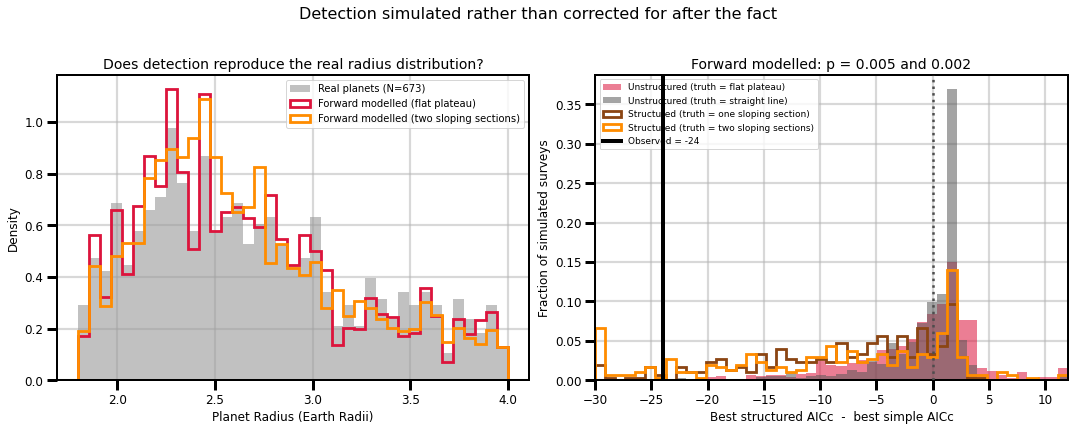

In [12]:
#### FORWARD MODELLING THE SURVEY INSTEAD OF PATCHING THE WEIGHTS ####
# The cell above showed both weightings are wrong. Freezing a planet's weight after
# changing its radius corrects it for a size it no longer has. Recomputing the weight
# fixes that but breaks something worse: it hands a fake planet placed at 1.85 R_Earth
# the large correction that only a genuinely detected 1.85 R_Earth planet has earned,
# because nothing in the simulation ever asked whether that planet would have been found.
#
# The fix is to make detection part of the generation. A real detected planet is not
# drawn from the intrinsic population, it is drawn from the intrinsic population filtered
# by whether the survey could see it, and its weight is the inverse of that filter. Doing
# the same thing in the simulation makes the radii and the weights consistent by
# construction, exactly as they are in the real data.
#
# Writing that out for one planet slot i, whose star temperature and orbital period are
# held at their real values:
#
#   intrinsic radius distribution  :  g(R - truth(Teff_i))
#   probability it is detected     :  d(R) = detection_rate * transit_prob at R's cell
#   detected radius distribution   :  proportional to g(R - truth(Teff_i)) * d(R)
#
# and g is recovered from the real residuals by undoing the same filter: the observed
# residuals follow g(u) * d(truth + u), so g is the residual distribution weighted by
# each planet's own completeness weight, which is 1/d at its own cell. That is already
# sitting in planets['weight'].
#
# So the whole forward model collapses to a weighted resample: draw residual j for slot i
# with probability proportional to
#
#   weight_j  *  d_i(truth_i + residual_j)
#
# the first factor undoing the detection that shaped the observed residuals, the second
# applying the detection appropriate to the slot the planet is landing in. Where the two
# slots have the same detectability the factors cancel and this reduces to the uniform
# resampling used in the earlier cells, so the difference is driven entirely by planets
# moving between cells of different completeness.
#
# Two things fall out for free. A radius that lands outside the grid has d = 0, so it is
# never drawn and the out-of-window leakage in the cell above disappears rather than
# defaulting to weight 1. And the fake weights are then just the grid values at the new
# radii, which is the recomputed scheme -- but now legitimate, because the radii were
# drawn with that same detection probability applied.

n_forward_simulations = 1000
n_forward_simulations_structured = 300
forward_rng = np.random.default_rng(11)

if 'weight_table' not in globals():
    raise RuntimeError('run the weights cell above first, this reuses its grid lookup')

raw_weights = planets['weight'].values.astype(float)


def build_draw_probabilities(truth_curve):
    # For every slot i and every candidate residual j, the chance that slot i ends up
    # holding a detected planet built from residual j
    candidates = truth_curve[:, None] + residual_pool_here[None, :]
    cells = cell_index(candidates.ravel(), radius_edges).reshape(candidates.shape)
    detectability = np.zeros_like(candidates)
    inside = np.isfinite(cells)
    rows = np.repeat(np.arange(n_planets), n_planets).reshape(candidates.shape)
    grid = weight_table[rows[inside], cells[inside].astype(int)]
    detectability[inside] = np.where(np.isfinite(grid), 1.0 / grid, 0.0)
    probability = detectability * raw_weights[None, :]
    total = probability.sum(axis=1, keepdims=True)
    # A slot with no reachable cell at all keeps the plain resample rather than vanishing
    dead = (total[:, 0] == 0)
    probability[dead] = 1.0
    total[dead] = n_planets
    return np.cumsum(probability / total, axis=1)


def forward_survey(cumulative, truth_curve):
    u = forward_rng.random(n_planets)
    picked = (cumulative < u[:, None]).sum(axis=1).clip(0, n_planets - 1)
    fake_radius = truth_curve + residual_pool_here[picked]
    return fake_radius, weights_for(fake_radius)


signature = cache_signature('cell11_forward', n_forward_simulations, n_forward_simulations_structured, n_planets, ladder_signature())
cached_result = load_cache('cell11_forward', signature)
if cached_result is None:
    forward = {}
    for label in truths:
        name, params = truths[label]
        truth_curve = models[name]['func'](teff, *params)
        residual_pool_here = residual_pool[label]
        cumulative = build_draw_probabilities(truth_curve)

        runs = n_forward_simulations if label in no_plateau else n_forward_simulations_structured
        gaps, offsets, escaped = [], [], []
        radius_sample = []
        for _ in range(runs):
            fake_radius, fake_weights = forward_survey(cumulative, truth_curve)
            gaps.append(aicc_gap(fit_ladder(teff, fake_radius, fake_weights)))
            offsets.append(np.median(fake_radius - truth_curve))
            escaped.append(np.mean((fake_radius < 1.8) | (fake_radius > 4.0)))
            if len(radius_sample) < 20:
                radius_sample.append(fake_radius)
        gaps = np.array(gaps)
        forward[label] = {'gap': gaps[np.isfinite(gaps)], 'runs': runs,
                          'offset': float(np.mean(offsets)), 'escaped': float(np.mean(escaped)),
                          'radius': np.concatenate(radius_sample)}
    save_cache('cell11_forward', signature, forward)
else:
    forward = cached_result

print("Validation of the forward model")
print("=" * 88)
print(f"  Real planets:   median radius {np.median(radius):.3f}, "
      f"16-84% {np.percentile(radius, 16):.2f}-{np.percentile(radius, 84):.2f} R_Earth")
for label in truths:
    sample = forward[label]['radius']
    print(f"  {label:<22} median radius {np.median(sample):.3f}, "
          f"16-84% {np.percentile(sample, 16):.2f}-{np.percentile(sample, 84):.2f}")

print(f"\n  The observed residuals sit {np.median(radius - models['Symmetric']['func'](teff, *ladder['Symmetric']['params'])):+.3f} "
      f"above the fitted curve, unweighted.")
print("  Detection should reproduce that offset without it being put in by hand:")
for label in truths:
    print(f"    {label:<22} generated offset {forward[label]['offset']:+.3f} R_Earth")

print("\n  Fake planets outside the 1.8-4.0 R_Earth window "
      "(was 2.4-3.1% before forward modelling):")
for label in truths:
    print(f"    {label:<22} {forward[label]['escaped']:.1%}")

print(f"\nObserved gap: {observed_gap_here:+.2f}")
print("=" * 88)
print(f"{'truth':<24}{'runs':>6}{'median gap':>13}{'reach observed':>17}{'p':>10}")
print("-" * 88)
for label in truths:
    gaps = forward[label]['gap']
    reached = int(np.sum(gaps <= observed_gap_here))
    print(f"{label:<24}{forward[label]['runs']:>6}{np.median(gaps):>+13.2f}"
          f"{f'{reached}/{len(gaps)}':>17}{reached / len(gaps):>10.4f}")

print("\nThe three schemes side by side")
print("-" * 88)
print(f"{'truth':<24}{'frozen':>12}{'recomputed':>14}{'forward':>12}")
for label in truths:
    forward_p = np.mean(forward[label]['gap'] <= observed_gap_here)
    print(f"{label:<24}{np.mean(results[label]['frozen'] <= observed_gap_here):>12.4f}"
          f"{np.mean(results[label]['correct'] <= observed_gap_here):>14.4f}"
          f"{forward_p:>12.4f}")

threshold_forward = min(np.percentile(forward[label]['gap'], 5) for label in no_plateau)
print(f"\n5% threshold from the forward-modelled nulls: {threshold_forward:+.2f}")
for label in has_plateau:
    power = np.mean(forward[label]['gap'] <= threshold_forward)
    print(f"  power against {label:<22} {power:>6.1%}   false negative {1 - power:>6.1%}")


# Create the plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
edges_radius = np.linspace(1.8, 4.0, 40)
ax.hist(radius, bins=edges_radius, density=True, color='0.6', alpha=0.6,
        label=f'Real planets (N={n_planets})')
for label, color in (('flat plateau', 'crimson'), ('two sloping sections', 'darkorange')):
    ax.hist(forward[label]['radius'], bins=edges_radius, density=True, histtype='step',
            linewidth=2.8, color=color, label=f'Forward modelled ({label})')
ax.set_xlabel('Planet Radius (Earth Radii)', size=12)
ax.set_ylabel('Density', size=12)
ax.set_title('Does detection reproduce the real radius distribution?', size=14)
ax.legend(loc='upper right', fontsize=10)

ax = axes[1]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
everything = np.concatenate([forward[l]['gap'] for l in truths])
low, high = np.floor(np.percentile(everything, 1)), 12
edges = np.linspace(low, high, 48)
for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35')):
    gaps = forward[label]['gap']
    ax.hist(np.clip(gaps, low, high), bins=edges, alpha=0.55, color=color,
            weights=np.full(len(gaps), 1 / len(gaps)),
            label=f'Unstructured (truth = {label})')
for label, color in (('one sloping section', 'saddlebrown'), ('two sloping sections', 'darkorange')):
    gaps = forward[label]['gap']
    ax.hist(np.clip(gaps, low, high), bins=edges, histtype='step', linewidth=2.8, color=color,
            weights=np.full(len(gaps), 1 / len(gaps)),
            label=f'Structured (truth = {label})')
ax.axvline(observed_gap_here, color='black', linewidth=4, zorder=6,
           label=f'Observed = {observed_gap_here:.0f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=3)
p_flat = np.mean(forward['flat plateau']['gap'] <= observed_gap_here)
p_line = np.mean(forward['straight line']['gap'] <= observed_gap_here)
ax.set_xlabel('Best structured AICc  -  best simple AICc', size=12)
ax.set_ylabel('Fraction of simulated surveys', size=12)
ax.set_xlim(low, high)
ax.set_title(f'Forward modelled: p = {p_flat:.3f} and {p_line:.3f}', size=14)
ax.legend(loc='upper left', fontsize=9)

for ax in axes:
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

fig.suptitle('Detection simulated rather than corrected for after the fact', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

fig.savefig('statistical_analysis_teff_forward_model.png', dpi=300, bbox_inches='tight')

  loaded cell12_medians_d from cache, computed 2026-10-16 17:15
Binned weighted medians of 1000 forward modelled surveys per model
Nothing is subtracted here. If detection and the weights are consistent, these
should sit on the true underlying model rather than above it.
------------------------------------------------------------------------------------
true underlying model              median offset from that model
  one sloping section                                  +0.0347 R_Earth
  two sloping sections                                 +0.0173 R_Earth
  flat plateau                                         +0.0008 R_Earth
  straight line                                        +0.0129 R_Earth

The fitted models the surveys are generated from
------------------------------------------------------------------------------------
  one sloping section    level 2.470 R_Earth, breakpoint 4314 K, slope 0.444 per 1000 K
  two sloping sections   level 2.462 R_Earth, breakpoints 4227 and 6108

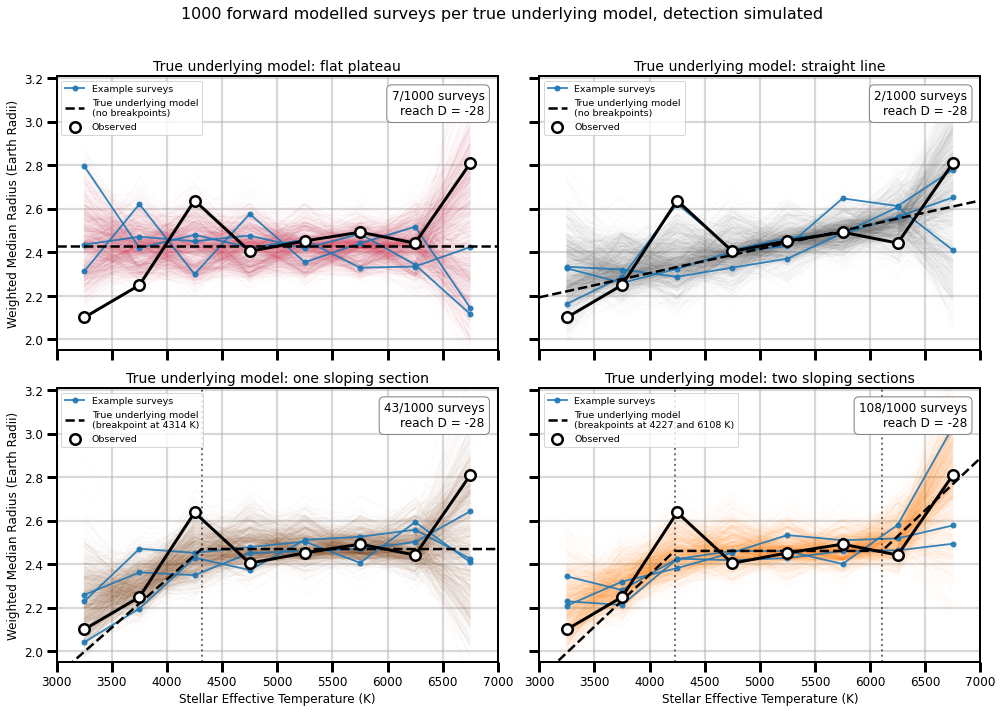

In [13]:
#### WHAT DO THE FORWARD MODELLED SURVEYS LOOK LIKE? ####
# The same picture as the generated-medians cell above, but for surveys built by
# simulating detection rather than by resampling residuals uniformly. Each thin line is
# one survey reduced to its binned weighted medians, with three drawn solid.
#
# There is one difference worth watching for. The earlier cell had to subtract a constant
# of about +0.18 R_Earth by hand, because uniform resampling adds the pool's unweighted
# centre while the fit enforces a weighted median of zero, so every generated survey sat
# that far above the real one. Nothing is subtracted here. The forward model applies
# detection on the way in and the weights undo it on the way out, so the binned weighted
# medians should land on the true underlying model by themselves. If they do, the correction
# doing its job; if they sit systematically high or low, it is not.

n_example_simulations = 1000
example_rng = np.random.default_rng(11)

# Which D values the panels quote. 'forward' uses the surveys drawn in this cell, so the
# counts describe the surveys actually plotted. 'resampled' uses the uniform-resampling
# run behind the D statistic table, so the figure and the table carry the same numbers.
# Both are already computed, so switching costs nothing but a redraw.
d_source = 'resampled'

for needed in ('weight_table', 'weights_for', 'build_draw_probabilities', 'binned_weighted_medians'):
    if needed not in globals():
        raise RuntimeError(f'{needed} is missing -- run the cells above first')


def binned_weighted_medians_with(sample_radius, sample_weights):
    # As the earlier helper, but each survey carries its own weights rather than the real ones
    medians = []
    for i in range(len(median_bins) - 1):
        bin_mask = (teff >= median_bins[i]) & (teff < median_bins[i + 1])
        if bin_mask.sum() < 2:
            medians.append(np.nan)
        else:
            medians.append(weighted_median(sample_radius[bin_mask], sample_weights[bin_mask]))
    return np.array(medians)


observed_medians_here = binned_weighted_medians(radius)

# The D statistic of each generated survey, so the counts quoted on the panels come from
# the same surveys that are drawn rather than from the uniform-resampling cell above
structured = ('Plateau+M', 'Symmetric')
simple = ('Plateau', 'Slope')


def likelihood_ratio_here(fitted):
    best_structured = min(fitted[m]['loss'] for m in structured)
    best_simple = min(fitted[m]['loss'] for m in simple)
    return 2 * n_planets * np.log(best_structured / best_simple)


observed_d = likelihood_ratio_here(ladder)

signature = cache_signature('cell12_medians_d', n_example_simulations, n_planets, ladder_signature())
cached_result = load_cache('cell12_medians_d', signature)
if cached_result is None:
    forward_medians = {}
    forward_d = {}
    for label in truths:
        name, params = truths[label]
        truth_curve = models[name]['func'](teff, *params)
        residual_pool_here = residual_pool[label]
        cumulative = build_draw_probabilities(truth_curve)

        lines, d_values = [], []
        for _ in range(n_example_simulations):
            u = example_rng.random(n_planets)
            picked = (cumulative < u[:, None]).sum(axis=1).clip(0, n_planets - 1)
            fake_radius = truth_curve + residual_pool_here[picked]
            fake_weights = weights_for(fake_radius)
            lines.append(binned_weighted_medians_with(fake_radius, fake_weights))
            d_values.append(likelihood_ratio_here(fit_ladder(teff, fake_radius, fake_weights)))
        forward_medians[label] = np.array(lines)
        forward_d[label] = np.array(d_values)
    save_cache('cell12_medians_d', signature, (forward_medians, forward_d))
else:
    forward_medians, forward_d = cached_result

print(f"Binned weighted medians of {n_example_simulations} forward modelled surveys per model")
print("=" * 84)
print("Nothing is subtracted here. If detection and the weights are consistent, these")
print("should sit on the true underlying model rather than above it.")
print("-" * 84)
print(f"{'true underlying model':<24}{'median offset from that model':>40}")
for label in truths:
    name, params = truths[label]
    truth_at_center = models[name]['func'](bin_centers, *params)
    offsets = forward_medians[label] - truth_at_center[None, :]
    print(f"  {label:<22}{np.nanmedian(offsets):>+38.4f} R_Earth")

print("\nThe fitted models the surveys are generated from")
print("-" * 84)
for label in truths:
    name, params = truths[label]
    if name == 'Plateau':
        print(f"  {label:<22} level {params[0]:.3f} R_Earth, no breakpoints")
    elif name == 'Slope':
        print(f"  {label:<22} {params[0]:.3f} R_Earth at {teff.min():.0f} K, "
              f"slope {params[1]*1000:.3f} per 1000 K, no breakpoints")
    elif name == 'Plateau+M':
        print(f"  {label:<22} level {params[0]:.3f} R_Earth, breakpoint {params[1]:.0f} K, "
              f"slope {params[2]*1000:.3f} per 1000 K")
    else:
        print(f"  {label:<22} level {params[0]:.3f} R_Earth, breakpoints {params[1]:.0f} "
              f"and {params[2]:.0f} K, slope {params[3]*1000:.3f} per 1000 K")

# Both sets are reported so the two generation schemes can be compared directly
panel_d, panel_observed = forward_d, observed_d
if d_source == 'resampled':
    if 'ratio_gaps' not in globals():
        raise RuntimeError("the no-penalty cell has not run, so its D values are unavailable")
    panel_d, panel_observed = ratio_gaps, observed_ratio

print(f"\nSurveys reaching the observed D statistic")
print("-" * 84)
print(f"{'true underlying model':<24}{'forward modelled':>22}{'uniform resampling':>24}")
for label in truths:
    forward_values = forward_d[label][np.isfinite(forward_d[label])]
    forward_text = (f"{int(np.sum(forward_values <= observed_d))}/{len(forward_values)}")
    if 'ratio_gaps' in globals():
        resampled_values = ratio_gaps[label][np.isfinite(ratio_gaps[label])]
        resampled_text = (f"{int(np.sum(resampled_values <= observed_ratio))}"
                          f"/{len(resampled_values)}")
    else:
        resampled_text = "not run"
    print(f"  {label:<22}{forward_text:>22}{resampled_text:>24}")
print(f"\n  observed D: forward modelled {observed_d:+.2f}, "
      f"uniform resampling {observed_ratio:+.2f}" if 'observed_ratio' in globals()
      else f"\n  observed D: {observed_d:+.2f}")
print(f"  panels quote the '{d_source}' values")

print("\nPercentile of the observed median within each model's simulated spread")
print("-" * 84)
for label in truths:
    places = []
    for i in range(len(bin_centers)):
        column = forward_medians[label][:, i]
        column = column[np.isfinite(column)]
        places.append(100 * np.mean(column <= observed_medians_here[i]))
    outside = sum(1 for p in places if p < 2.5 or p > 97.5)
    print(f"  {label:<22}" + "".join(f"{p:>6.0f}" for p in places)
          + f"   ({outside} of {len(places)} bins outside 2.5-97.5%)")


# Create the plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

panels = [
    ('flat plateau', 'crimson'),
    ('straight line', '0.35'),
    ('one sloping section', 'saddlebrown'),
    ('two sloping sections', 'darkorange'),
]
x_line = np.linspace(median_bins[0], median_bins[-1], 400)
for ax, (label, color) in zip(axes.flat, panels):
    ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    # Every forward modelled survey as one faint line
    for line in forward_medians[label]:
        ax.plot(bin_centers, line, color=color, alpha=0.025, linewidth=0.8, zorder=2)

    # Three of them drawn solid
    for j in range(3):
        ax.plot(bin_centers, forward_medians[label][j], color='tab:blue', linewidth=1.8,
                alpha=0.9, marker='o', markersize=5, zorder=3,
                label='Example surveys' if j == 0 else None)

    name, params = truths[label]
    # The fitted breakpoints, marked where they fall and quoted on the model line
    breakpoints = []
    if name == 'Plateau+M':
        breakpoints = [params[1]]
    elif name == 'Symmetric':
        breakpoints = [params[1], params[2]]
    for breakpoint in breakpoints:
        ax.axvline(breakpoint, color='black', linestyle=':', linewidth=2, alpha=0.55, zorder=4)
    if breakpoints:
        quoted = ' and '.join(f'{breakpoint:.0f}' for breakpoint in breakpoints)
        word = 'breakpoint' if len(breakpoints) == 1 else 'breakpoints'
        model_label = f'True underlying model\n({word} at {quoted} K)'
    else:
        model_label = 'True underlying model\n(no breakpoints)'
    ax.plot(x_line, models[name]['func'](x_line, *params), color='black', linestyle='--',
            linewidth=2.5, zorder=5, label=model_label)
    ax.plot(bin_centers, observed_medians_here, color='black', linewidth=3, zorder=5)
    ax.scatter(bin_centers, observed_medians_here, s=110, facecolor='white', edgecolor='black',
               linewidth=2.5, zorder=6, label='Observed')

    d_values = panel_d[label]
    d_values = d_values[np.isfinite(d_values)]
    reached = int(np.sum(d_values <= panel_observed))
    ax.text(0.97, 0.95, f'{reached}/{len(d_values)} surveys\nreach D = {panel_observed:.0f}',
            transform=ax.transAxes, ha='right', va='top', size=12, zorder=7,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='0.5'))

    ax.set_title(f'True underlying model: {label}', size=14)
    ax.legend(loc='upper left', fontsize=9.5)
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

spread = np.concatenate([forward_medians[l].ravel() for l in truths])
spread = spread[np.isfinite(spread)]
axes[0, 0].set_ylim(np.nanpercentile(spread, 0.2) - 0.05, np.nanpercentile(spread, 99.8) + 0.05)
axes[0, 0].set_xlim(median_bins[0], median_bins[-1])
for ax in axes[1, :]:
    ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
for ax in axes[:, 0]:
    ax.set_ylabel('Weighted Median Radius (Earth Radii)', size=12)

fig.suptitle(f'{n_example_simulations} forward modelled surveys per true underlying model, '
             'detection simulated', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

fig.savefig('statistical_analysis_teff_forward_medians.png', dpi=300, bbox_inches='tight')

One forward modelled survey per true underlying model, 673 planets each
                           median R          16-84%     min     max   mean weight
------------------------------------------------------------------------------------
real survey                   2.610       2.13-3.37    1.80    4.00         1.000
one sloping section           2.535       2.13-3.20    1.80    4.00         0.968
two sloping sections          2.527       2.16-3.24    1.81    4.00         0.970
flat plateau                  2.534       2.16-3.33    1.81    4.00         1.001
straight line                 2.576       2.14-3.31    1.80    3.98         0.999


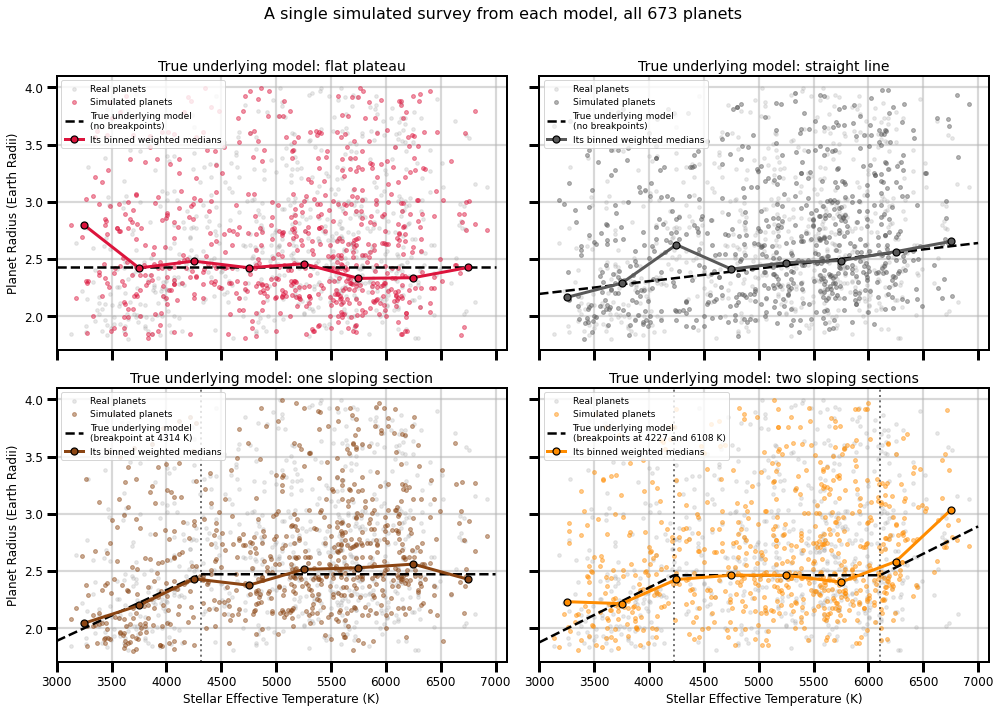

In [14]:
#### ONE FORWARD MODELLED SURVEY PER MODEL, PLANET BY PLANET ####
# The cells above show the simulated surveys reduced to eight binned medians. This shows
# what one of them actually is: 673 individual planets, the same number as the real
# survey, on the same stars at the same orbital periods, with only the radii replaced.
#
# The real planets are underneath in grey so the two can be compared directly. The dashed
# line is the true underlying model the survey was generated from, and the solid line is
# own binned weighted medians, which is one of the faint lines in the figure above.
#
# The seed and the draw order match the previous cell, so these are its first example
# survey in each panel rather than fresh draws.

if 'build_draw_probabilities' not in globals():
    # Rebuild the grid lookup and the generator without rerunning any of the simulations
    # that cells 10 and 11 carry. Nothing here takes more than a second.
    print("Rebuilding the forward model helpers: cells 10 and 11 were not run in this kernel\n")

    grid_weight = {}
    for row in completeness.itertuples():
        if np.isfinite(row.radius_cell) and np.isfinite(row.period_cell):
            grid_weight[(row.teff_bin, int(row.radius_cell), int(row.period_cell))] = (
                1 / row.detection_rate * 1 / row.transit_prob)

    radius_cells = sorted(int(c) for c in completeness['radius_cell'].dropna().unique())
    weight_table = np.full((n_planets, max(radius_cells) + 1), np.nan)
    for i, planet in enumerate(planets.itertuples()):
        if not np.isfinite(planet.period_cell):
            continue
        for cell in radius_cells:
            found = grid_weight.get((planet.teff_bin, cell, int(planet.period_cell)))
            if found is not None:
                weight_table[i, cell] = found

    raw_weights = planets['weight'].values.astype(float)
    raw_mean = raw_weights.mean()

    def weights_for(sample_radius):
        cells = cell_index(sample_radius, radius_edges)
        found = np.full(n_planets, np.nan)
        inside = np.isfinite(cells)
        rows = np.arange(n_planets)[inside]
        found[inside] = weight_table[rows, cells[inside].astype(int)]
        found = np.where(np.isfinite(found), found, 1.0)
        return found / raw_mean

    def build_draw_probabilities(truth_curve):
        candidates = truth_curve[:, None] + residual_pool_here[None, :]
        cells = cell_index(candidates.ravel(), radius_edges).reshape(candidates.shape)
        detectability = np.zeros_like(candidates)
        inside = np.isfinite(cells)
        rows = np.repeat(np.arange(n_planets), n_planets).reshape(candidates.shape)
        grid = weight_table[rows[inside], cells[inside].astype(int)]
        detectability[inside] = np.where(np.isfinite(grid), 1.0 / grid, 0.0)
        probability = detectability * raw_weights[None, :]
        total = probability.sum(axis=1, keepdims=True)
        dead = (total[:, 0] == 0)
        probability[dead] = 1.0
        total[dead] = n_planets
        return np.cumsum(probability / total, axis=1)


n_example_simulations = 1000
example_rng = np.random.default_rng(11)

example_survey = {}
for label in truths:
    name, params = truths[label]
    truth_curve = models[name]['func'](teff, *params)
    residual_pool_here = residual_pool[label]
    cumulative = build_draw_probabilities(truth_curve)

    # The draws are stepped through in the same order as the cell above so the survey
    # kept here is the one drawn as its first example line, not an unrelated one
    kept = None
    for run in range(n_example_simulations):
        u = example_rng.random(n_planets)
        picked = (cumulative < u[:, None]).sum(axis=1).clip(0, n_planets - 1)
        if run == 0:
            kept = truth_curve + residual_pool_here[picked]
    example_survey[label] = (kept, weights_for(kept))

print(f"One forward modelled survey per true underlying model, {n_planets} planets each")
print("=" * 84)
print(f"{'':<24}{'median R':>11}{'16-84%':>16}{'min':>8}{'max':>8}{'mean weight':>14}")
print("-" * 84)
print(f"{'real survey':<24}{np.median(radius):>11.3f}"
      f"{f'{np.percentile(radius, 16):.2f}-{np.percentile(radius, 84):.2f}':>16}"
      f"{radius.min():>8.2f}{radius.max():>8.2f}{weights.mean():>14.3f}")
for label in truths:
    sample, sample_weights = example_survey[label]
    print(f"{label:<24}{np.median(sample):>11.3f}"
          f"{f'{np.percentile(sample, 16):.2f}-{np.percentile(sample, 84):.2f}':>16}"
          f"{sample.min():>8.2f}{sample.max():>8.2f}{sample_weights.mean():>14.3f}")


# Create the plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

panels = [
    ('flat plateau', 'crimson'),
    ('straight line', '0.35'),
    ('one sloping section', 'saddlebrown'),
    ('two sloping sections', 'darkorange'),
]
x_line = np.linspace(median_bins[0], median_bins[-1], 400)
for ax, (label, color) in zip(axes.flat, panels):
    ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    # The real planets underneath for comparison
    ax.scatter(teff, radius, s=13, color='0.6', alpha=0.22, zorder=2,
               label='Real planets')

    # The simulated survey
    sample, sample_weights = example_survey[label]
    ax.scatter(teff, sample, s=15, color=color, alpha=0.45, zorder=3,
               label='Simulated planets')

    name, params = truths[label]
    # The fitted breakpoints, marked where they fall and quoted on the model line
    breakpoints = []
    if name == 'Plateau+M':
        breakpoints = [params[1]]
    elif name == 'Symmetric':
        breakpoints = [params[1], params[2]]
    for breakpoint in breakpoints:
        ax.axvline(breakpoint, color='black', linestyle=':', linewidth=2, alpha=0.55, zorder=4)
    if breakpoints:
        quoted = ' and '.join(f'{breakpoint:.0f}' for breakpoint in breakpoints)
        word = 'breakpoint' if len(breakpoints) == 1 else 'breakpoints'
        model_label = f'True underlying model\n({word} at {quoted} K)'
    else:
        model_label = 'True underlying model\n(no breakpoints)'
    ax.plot(x_line, models[name]['func'](x_line, *params), color='black', linestyle='--',
            linewidth=2.5, zorder=5, label=model_label)

    medians = []
    for i in range(len(median_bins) - 1):
        bin_mask = (teff >= median_bins[i]) & (teff < median_bins[i + 1])
        if bin_mask.sum() < 2:
            medians.append(np.nan)
        else:
            medians.append(weighted_median(sample[bin_mask], sample_weights[bin_mask]))
    ax.plot(bin_centers, medians, color=color, linewidth=3, marker='o', markersize=7,
            markeredgecolor='black', markeredgewidth=1.2, zorder=6,
            label='Its binned weighted medians')

    ax.set_title(f'True underlying model: {label}', size=14)
    ax.legend(loc='upper left', fontsize=9)
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

axes[0, 0].set_xlim(3000, 7100)
axes[0, 0].set_ylim(1.7, 4.1)
for ax in axes[1, :]:
    ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
for ax in axes[:, 0]:
    ax.set_ylabel('Planet Radius (Earth Radii)', size=12)

fig.suptitle('A single simulated survey from each model, all 673 planets', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

fig.savefig('statistical_analysis_teff_example_surveys.png', dpi=300, bbox_inches='tight')

  loaded cell14_rolling from cache, computed 2026-10-01 16:11
Rolling weighted median of all 673 planets, no bins
Teff (K)         window 51    window 101    window 201
------------------------------------------------------------------------------
3300                 2.088         2.103         2.214
3800                 2.249         2.293         2.301
4300                 2.667         2.516         2.354
4800                 2.558         2.510         2.529
5300                 2.427         2.450         2.491
5800                 2.434         2.431         2.434
6300                 2.482         2.606         2.456
6800                 2.772         2.558         2.529

Window of 101 planets spans, in temperature:
  near 3300 K: 3131-3668 K (537 K wide)
  near 5300 K: 5126-5511 K (385 K wide)
  near 6800 K: 6225-6920 K (695 K wide)

Fitted breakpoints for comparison: 4227 K and 6108 K


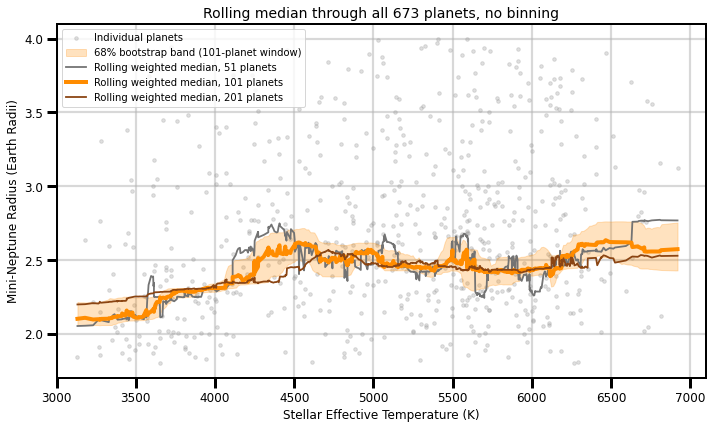

In [15]:
#### THE DATA WITH A ROLLING MEDIAN INSTEAD OF BINNED POINTS ####
# Every figure so far reduces the survey to eight binned medians, which is what the
# referee objected to: the answer moves when the edges move, and eight points throw away
# most of the sample. A rolling median has no edges at all. Each planet gets the weighted
# median of its nearest neighbours in temperature, so the curve is continuous and nothing
# depends on where a bin boundary happens to fall.
#
# The window is a fixed number of planets rather than a fixed width in Kelvin, because
# the sampling is very uneven -- 168 planets between 5500 and 6000 K against 18 above
# 6500 K. A fixed width would be smooth in the middle and unusable at the ends; a fixed
# count keeps the noise roughly constant and lets the resolution vary instead.
#
# Three window sizes are drawn so the structure can be told apart from the smoothing.
# A feature that only appears at one window size is a property of the window.

window_sizes = [51, 101, 201]
n_rolling_bootstrap = 300
rolling_rng = np.random.default_rng(11)

if 'weighted_median' not in globals():
    def weighted_median(values, w):
        order = np.argsort(values)
        values, w = values[order], w[order]
        cumulative = np.cumsum(w) - 0.5 * w
        return np.interp(0.5 * np.sum(w), cumulative, values)


def rolling_median(sample_teff, sample_radius, sample_weights, window):
    # Weighted median of the nearest `window` planets in temperature, centred on each
    # planet in turn. The window is clipped at the two ends rather than padded, so the
    # first and last points average over fewer neighbours on one side.
    order = np.argsort(sample_teff)
    sorted_teff = sample_teff[order]
    sorted_radius = sample_radius[order]
    sorted_weights = sample_weights[order]
    half = window // 2
    centers, medians = [], []
    for i in range(len(sorted_teff)):
        lo = max(0, i - half)
        hi = min(len(sorted_teff), i + half + 1)
        centers.append(sorted_teff[i])
        medians.append(weighted_median(sorted_radius[lo:hi], sorted_weights[lo:hi]))
    return np.array(centers), np.array(medians)


signature = cache_signature('cell14_rolling', tuple(window_sizes), n_rolling_bootstrap,
                            n_planets, ladder_signature())
cached_result = load_cache('cell14_rolling', signature)
if cached_result is None:
    curves = {}
    for window in window_sizes:
        curves[window] = rolling_median(teff, radius, weights, window)

    # Bootstrap band for the middle window, evaluated on a common grid so the percentiles
    # can be taken pointwise
    grid = np.linspace(teff.min(), teff.max(), 300)
    band = []
    for _ in range(n_rolling_bootstrap):
        pick = rolling_rng.integers(0, n_planets, size=n_planets)
        centers, medians = rolling_median(teff[pick], radius[pick], weights[pick],
                                          window_sizes[1])
        band.append(np.interp(grid, centers, medians))
    band = np.array(band)
    save_cache('cell14_rolling', signature, (curves, grid, band))
else:
    curves, grid, band = cached_result

lower = np.percentile(band, 16, axis=0)
upper = np.percentile(band, 84, axis=0)

print(f"Rolling weighted median of all {n_planets} planets, no bins")
print("=" * 78)
print(f"{'Teff (K)':<12}" + "".join(f"{'window ' + str(w):>14}" for w in window_sizes))
print("-" * 78)
for temperature in (3300, 3800, 4300, 4800, 5300, 5800, 6300, 6800):
    print(f"{temperature:<12}", end='')
    for window in window_sizes:
        centers, medians = curves[window]
        print(f"{np.interp(temperature, centers, medians):>14.3f}", end='')
    print()

centers, medians = curves[window_sizes[1]]
print(f"\nWindow of {window_sizes[1]} planets spans, in temperature:")
for temperature in (3300, 5300, 6800):
    i = np.argmin(np.abs(centers - temperature))
    half = window_sizes[1] // 2
    lo, hi = max(0, i - half), min(len(centers), i + half + 1)
    print(f"  near {temperature} K: {centers[lo]:.0f}-{centers[hi-1]:.0f} K "
          f"({centers[hi-1] - centers[lo]:.0f} K wide)")

print(f"\nFitted breakpoints for comparison: "
      f"{ladder['Symmetric']['params'][1]:.0f} K and {ladder['Symmetric']['params'][2]:.0f} K")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Individual planet radii as grey transparent dots
ax.scatter(teff, radius, s=13, color='0.6', alpha=0.3, zorder=2, label='Individual planets')

ax.fill_between(grid, lower, upper, color='darkorange', alpha=0.25, zorder=3,
                label=f'68% bootstrap band ({window_sizes[1]}-planet window)')

shades = ['0.45', 'darkorange', 'saddlebrown']
widths = [1.8, 4.0, 1.8]
for window, shade, width in zip(window_sizes, shades, widths):
    centers, medians = curves[window]
    ax.plot(centers, medians, color=shade, linewidth=width, zorder=5,
            label=f'Rolling weighted median, {window} planets')

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Mini-Neptune Radius (Earth Radii)', size=12)
ax.set_xlim(3000, 7100)
ax.set_ylim(1.7, 4.1)
ax.set_title(f'Rolling median through all {n_planets} planets, no binning', size=14)
ax.legend(loc='upper left', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_rolling_median.png', dpi=300, bbox_inches='tight')

Illustration built from the plateau with two slopes model
  example slot: planet 344, Teff 4998 K, model median 2.462 R_Earth
  real radius 2.753, simulated radius 2.903

  mean radius of the whole simulated survey: 2.670 (real 2.701)
  mean weight: 0.960 (real 1.000)

  Mean resulting radius for the example slot under each draw rule:
    Uniform draw: detection as in the observed pool 2.735 R_Earth
    Donor weight only: detection removed 2.586 R_Earth
    New detectability only: detection counted twice 2.834 R_Earth
    Used here: detection re-applied for this slot 2.680 R_Earth


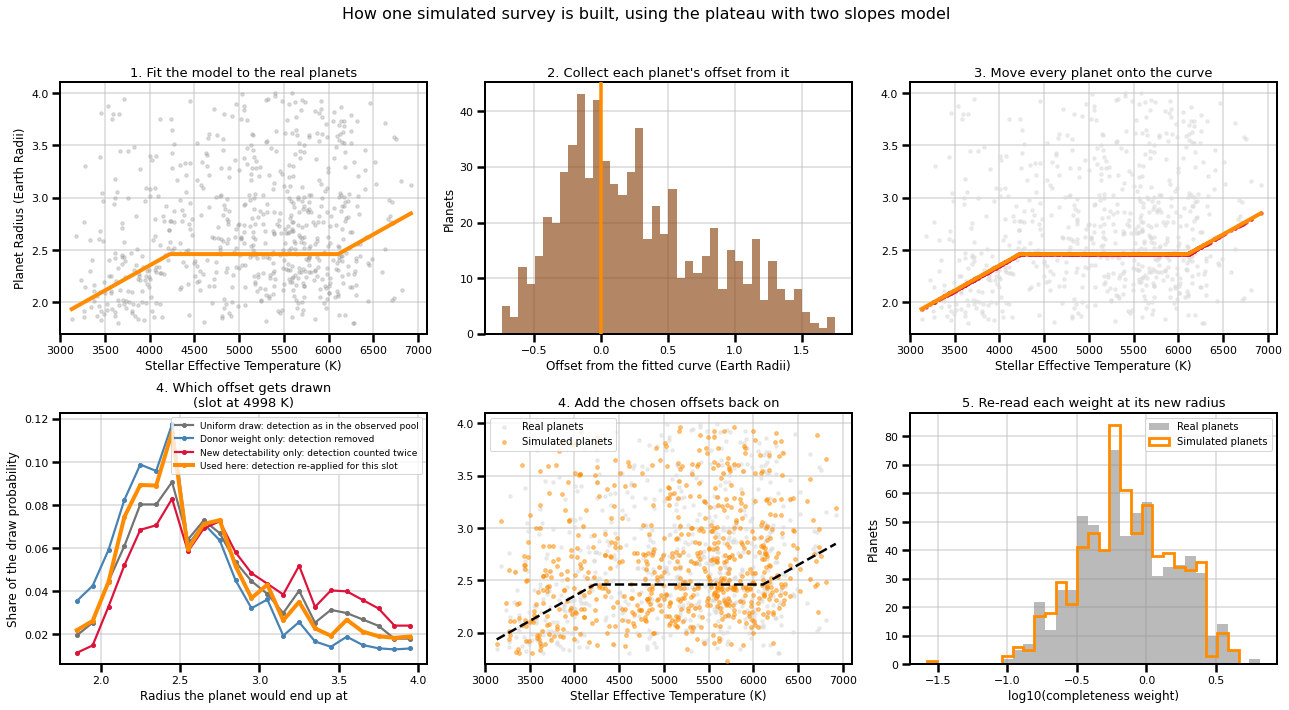

In [16]:
#### THE GENERATION PROCEDURE, DRAWN OUT STEP BY STEP ####
# Six panels following one simulated survey from the real data to the finished fake,
# using the two-sloping-section model as the example. The middle panel of the bottom row
# is the one worth studying: it shows why the draw needs both completeness factors and
# not just one.

example_model = 'Symmetric'
example_label = 'plateau with two slopes'
example_slot = int(np.argmin(np.abs(teff - 5000)))

if 'build_draw_probabilities' not in globals():
    raise RuntimeError('run the forward model cells above first')

truth_curve = models[example_model]['func'](teff, *ladder[example_model]['params'])
residual_pool_here = radius - truth_curve
cumulative = build_draw_probabilities(truth_curve)

illustration_rng = np.random.default_rng(11)
u = illustration_rng.random(n_planets)
picked = (cumulative < u[:, None]).sum(axis=1).clip(0, n_planets - 1)
fake_radius = truth_curve + residual_pool_here[picked]
fake_weights = weights_for(fake_radius)

# The three candidate draw rules for the example slot, as a function of the radius the
# planet would end up with
candidates = truth_curve[example_slot] + residual_pool_here
cells = cell_index(candidates, radius_edges)
detectability = np.zeros(n_planets)
inside = np.isfinite(cells)
grid = weight_table[example_slot, cells[inside].astype(int)]
detectability[inside] = np.where(np.isfinite(grid), 1.0 / grid, 0.0)

rules = {
    'Uniform draw: detection as in the observed pool': np.ones(n_planets),
    'Donor weight only: detection removed': raw_weights.copy(),
    'New detectability only: detection counted twice': detectability,
    'Used here: detection re-applied for this slot': detectability * raw_weights,
}
radius_bins = np.linspace(1.8, 4.0, 23)
radius_centers = 0.5 * (radius_bins[:-1] + radius_bins[1:])
binned_rules = {}
for name in rules:
    share = rules[name] / rules[name].sum()
    totals = []
    for i in range(len(radius_bins) - 1):
        in_bin = (candidates >= radius_bins[i]) & (candidates < radius_bins[i + 1])
        totals.append(share[in_bin].sum())
    binned_rules[name] = np.array(totals)

print(f"Illustration built from the {example_label} model")
print("=" * 78)
print(f"  example slot: planet {example_slot}, Teff {teff[example_slot]:.0f} K, "
      f"model median {truth_curve[example_slot]:.3f} R_Earth")
print(f"  real radius {radius[example_slot]:.3f}, simulated radius {fake_radius[example_slot]:.3f}")
print(f"\n  mean radius of the whole simulated survey: {fake_radius.mean():.3f} "
      f"(real {radius.mean():.3f})")
print(f"  mean weight: {fake_weights.mean():.3f} (real {weights.mean():.3f})")
print("\n  Mean resulting radius for the example slot under each draw rule:")
for name in rules:
    share = rules[name] / rules[name].sum()
    print(f"    {name:<30} {np.sum(share * candidates):.3f} R_Earth")


# Create the plot
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax in axes.flat:
    ax.grid(True, which='major', linewidth=2.0, alpha=0.45, color='0.75')
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', which='major', width=2.5, length=8, labelsize=11)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

x_line = np.linspace(teff.min(), teff.max(), 400)
model_line = models[example_model]['func'](x_line, *ladder[example_model]['params'])

# Step 1: fit the model to the real planets
ax = axes[0, 0]
ax.scatter(teff, radius, s=12, color='0.6', alpha=0.35, zorder=2)
ax.plot(x_line, model_line, color='darkorange', linewidth=4, zorder=5)
ax.set_title('1. Fit the model to the real planets', size=13)
ax.set_ylabel('Planet Radius (Earth Radii)', size=12)

# Step 2: the scatter about that fitted curve
ax = axes[0, 1]
ax.hist(residual_pool_here, bins=40, color='saddlebrown', alpha=0.65)
ax.axvline(0, color='darkorange', linewidth=3.5, zorder=5)
ax.set_title('2. Collect each planet\'s offset from it', size=13)
ax.set_xlabel('Offset from the fitted curve (Earth Radii)', size=12)
ax.set_ylabel('Planets', size=12)

# Step 3: every planet moved onto the curve
ax = axes[0, 2]
ax.scatter(teff, radius, s=12, color='0.85', alpha=0.5, zorder=2)
ax.scatter(teff, truth_curve, s=12, color='crimson', alpha=0.6, zorder=3)
ax.plot(x_line, model_line, color='darkorange', linewidth=4, zorder=5)
ax.set_title('3. Move every planet onto the curve', size=13)

# Step 4a: how the offset is chosen, for one slot
ax = axes[1, 0]
colors = {'Uniform draw: detection as in the observed pool': '0.45',
          'Donor weight only: detection removed': 'steelblue',
          'New detectability only: detection counted twice': 'crimson',
          'Used here: detection re-applied for this slot': 'darkorange'}
widths = {'Uniform draw: detection as in the observed pool': 2.2,
          'Donor weight only: detection removed': 2.2,
          'New detectability only: detection counted twice': 2.2,
          'Used here: detection re-applied for this slot': 4.0}
for name in rules:
    ax.plot(radius_centers, binned_rules[name], color=colors[name], linewidth=widths[name],
            marker='o', markersize=4, zorder=5, label=name)
ax.set_title(f'4. Which offset gets drawn\n(slot at {teff[example_slot]:.0f} K)', size=13)
ax.set_xlabel('Radius the planet would end up at', size=12)
ax.set_ylabel('Share of the draw probability', size=12)
ax.legend(loc='upper right', fontsize=9)

# Step 4b: the finished simulated survey
ax = axes[1, 1]
ax.scatter(teff, radius, s=12, color='0.85', alpha=0.5, zorder=2, label='Real planets')
ax.scatter(teff, fake_radius, s=14, color='darkorange', alpha=0.5, zorder=3,
           label='Simulated planets')
ax.plot(x_line, model_line, color='black', linestyle='--', linewidth=2.5, zorder=5)
ax.set_title('4. Add the chosen offsets back on', size=13)
ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.legend(loc='upper left', fontsize=10)

# Step 5: weights re-read at the new radii
ax = axes[1, 2]
edges_weight = np.linspace(np.log10(min(weights.min(), fake_weights.min())),
                           np.log10(max(weights.max(), fake_weights.max())), 32)
ax.hist(np.log10(weights), bins=edges_weight, color='0.55', alpha=0.6, label='Real planets')
ax.hist(np.log10(fake_weights), bins=edges_weight, histtype='step', linewidth=2.8,
        color='darkorange', label='Simulated planets')
ax.set_title('5. Re-read each weight at its new radius', size=13)
ax.set_xlabel('log10(completeness weight)', size=12)
ax.set_ylabel('Planets', size=12)
ax.legend(loc='upper right', fontsize=10)

for ax in (axes[0, 0], axes[0, 2], axes[1, 1]):
    ax.set_xlim(3000, 7100)
    ax.set_ylim(1.7, 4.1)
axes[0, 0].set_xlabel('Stellar Effective Temperature (K)', size=12)
axes[0, 2].set_xlabel('Stellar Effective Temperature (K)', size=12)

fig.suptitle(f'How one simulated survey is built, using the {example_label} model', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

fig.savefig('statistical_analysis_teff_generation_steps.png', dpi=300, bbox_inches='tight')

  loaded cell16_asymmetric from cache, computed 2026-10-01 19:34
Five-parameter fit with the two slopes free, against the four-parameter version
Model           k   check loss       AICc    dAICc
------------------------------------------------------------------------------
Plateau         1      134.852    1050.18    50.00
Slope           2      132.171    1025.16    24.98
Plateau+M       3      130.648    1011.57    11.39
Symmetric       4      129.446    1001.16     0.98
Asymmetric      5      129.157    1000.18     0.00

Symmetric  c=2.462, x1=4227 K, x2=6108 K, s=0.4786 per 1000 K
Asymmetric c=2.455, x1=4306 K, x2=6304 K, s1=0.4309, s2=0.9402 per 1000 K

Bootstrap over 460 resamples of the 673 planets
------------------------------------------------------------------------------
  30 of 460 resamples (6.5%) put a breakpoint on the edge of the range and are dropped
  cool slope s1   +0.3491 [+0.1434, +0.4925] per 1000 K
  hot slope  s2   +0.6756 [+0.3840, +1.2954] per 1000 K
  s1 -

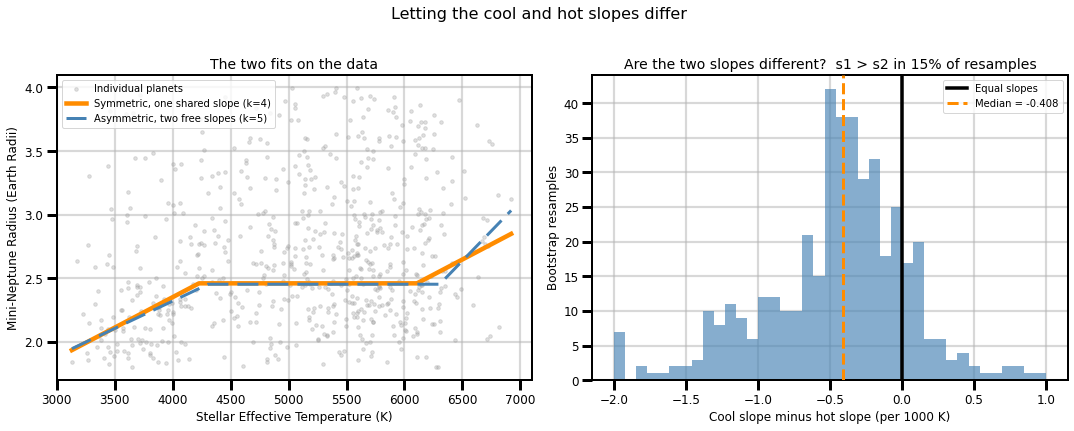

In [17]:
#### DOES FORCING THE TWO SLOPES TO BE EQUAL COST ANYTHING? ####
# The Symmetric model ties the cool-end and hot-end slopes to a single value, which is an
# assumption nothing above has tested. This fits the same shape with the two slopes free,
# a fifth parameter, and asks two questions: does the extra freedom buy enough fit to pay
# for itself, and are the two slopes actually different.
#
# The second question is the interesting one for the paper. If the fitted slopes come out
# consistent with each other, the symmetric model is not imposing anything the data
# object to. If they come out clearly different, the symmetric form is forcing the cool
# and hot ends to compromise, and the breakpoints it reports are affected.

n_slope_bootstrap = 500
slope_rng = np.random.default_rng(11)


def asymmetric(x, c, x1, x2, s1, s2):
    # Rise with slope s1 below x1, flat at c between the breakpoints, rise with s2 above x2
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s1 * (x - x1), np.full_like(x, c), c + s2 * (x - x2)],
    )


def fit_asymmetric(sample_teff, sample_radius, sample_weights):
    # Same search as fit_model, with the extra slope and the breakpoints kept in order
    span = x_max - x_min
    level = np.median(sample_radius)
    cool = sample_teff < np.median(sample_teff)
    gradient = (np.median(sample_radius[~cool]) - np.median(sample_radius[cool])) / span
    best_loss, best_params = np.inf, None
    for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55), (0.45, 0.85), (0.35, 0.6)):
        guess = [level, x_min + a * span, x_min + b * span, gradient, gradient]
        result = minimize(
            lambda p: check_loss(asymmetric, p, sample_teff, sample_radius, sample_weights),
            guess, method='Powell', options={'maxiter': 20000, 'xtol': 1e-4, 'ftol': 1e-6})
        params = np.array(result.x, dtype=float)
        params[1] = np.clip(params[1], x_min, x_max)
        params[2] = np.clip(params[2], x_min, x_max)
        if params[1] > params[2]:
            continue
        loss = check_loss(asymmetric, params, sample_teff, sample_radius, sample_weights)
        if np.isfinite(loss) and loss < best_loss:
            best_loss, best_params = loss, params
    return best_loss, best_params


asymmetric_loss, asymmetric_params = fit_asymmetric(teff, radius, weights)

signature = cache_signature('cell16_asymmetric', n_slope_bootstrap, n_planets, ladder_signature())
cached_result = load_cache('cell16_asymmetric', signature)
if cached_result is None:
    bootstrap_slopes = []
    for _ in range(n_slope_bootstrap):
        pick = slope_rng.integers(0, n_planets, size=n_planets)
        loss, params = fit_asymmetric(teff[pick], radius[pick], weights[pick])
        if params is not None:
            bootstrap_slopes.append(params)
    bootstrap_slopes = np.array(bootstrap_slopes)
    save_cache('cell16_asymmetric', signature, bootstrap_slopes)
else:
    bootstrap_slopes = cached_result


def aicc_from(loss, k):
    sigma = loss / n_planets
    log_likelihood = n_planets * np.log(0.25) - n_planets * np.log(sigma) - n_planets
    return -2 * log_likelihood + 2 * k + 2 * k * (k + 1) / (n_planets - k - 1)


asymmetric_aicc = aicc_from(asymmetric_loss, 5)
best_aicc_here = min([ladder[name]['AICc'] for name in ladder] + [asymmetric_aicc])

print(f"Five-parameter fit with the two slopes free, against the four-parameter version")
print("=" * 78)
print(f"{'Model':<14}{'k':>3}{'check loss':>13}{'AICc':>11}{'dAICc':>9}")
print("-" * 78)
for name in ladder:
    print(f"{name:<14}{ladder[name]['k']:>3}{ladder[name]['loss']:>13.3f}"
          f"{ladder[name]['AICc']:>11.2f}{ladder[name]['AICc'] - best_aicc_here:>9.2f}")
print(f"{'Asymmetric':<14}{5:>3}{asymmetric_loss:>13.3f}"
      f"{asymmetric_aicc:>11.2f}{asymmetric_aicc - best_aicc_here:>9.2f}")

symmetric_params = ladder['Symmetric']['params']
print(f"\nSymmetric  c={symmetric_params[0]:.3f}, x1={symmetric_params[1]:.0f} K, "
      f"x2={symmetric_params[2]:.0f} K, s={symmetric_params[3]*1000:.4f} per 1000 K")
print(f"Asymmetric c={asymmetric_params[0]:.3f}, x1={asymmetric_params[1]:.0f} K, "
      f"x2={asymmetric_params[2]:.0f} K, "
      f"s1={asymmetric_params[3]*1000:.4f}, s2={asymmetric_params[4]*1000:.4f} per 1000 K")

# A fifth parameter is enough to let a breakpoint slide onto the edge of the range, where
# the segment beyond it holds almost no planets and its slope runs away to any value. Those
# resamples are not fits, they are the optimiser falling off the end, so they are counted
# and dropped rather than left to wreck the percentiles.
margin = 100.0
usable = ((bootstrap_slopes[:, 1] > x_min + margin) & (bootstrap_slopes[:, 1] < x_max - margin)
          & (bootstrap_slopes[:, 2] > x_min + margin) & (bootstrap_slopes[:, 2] < x_max - margin)
          & (np.abs(bootstrap_slopes[:, 3]) * 1000 < 5) & (np.abs(bootstrap_slopes[:, 4]) * 1000 < 5))
print(f"\nBootstrap over {len(bootstrap_slopes)} resamples of the {n_planets} planets")
print("-" * 78)
print(f"  {np.sum(~usable)} of {len(bootstrap_slopes)} resamples ({np.mean(~usable):.1%}) put a "
      f"breakpoint on the edge of the range and are dropped")
cool_slope = bootstrap_slopes[usable, 3] * 1000
hot_slope = bootstrap_slopes[usable, 4] * 1000
difference = cool_slope - hot_slope
print(f"  cool slope s1  {np.median(cool_slope):>+8.4f} "
      f"[{np.percentile(cool_slope, 16):+.4f}, {np.percentile(cool_slope, 84):+.4f}] per 1000 K")
print(f"  hot slope  s2  {np.median(hot_slope):>+8.4f} "
      f"[{np.percentile(hot_slope, 16):+.4f}, {np.percentile(hot_slope, 84):+.4f}] per 1000 K")
print(f"  s1 - s2        {np.median(difference):>+8.4f} "
      f"[{np.percentile(difference, 16):+.4f}, {np.percentile(difference, 84):+.4f}]")
print(f"  fraction of resamples with s1 > s2: {np.mean(difference > 0):.1%}")
print(f"  fraction with the hot slope negative: {np.mean(hot_slope < 0):.1%}")

print(f"\nBreakpoints under the five-parameter fit")
print("-" * 78)
print(f"  x1  {np.median(bootstrap_slopes[usable, 1]):>6.0f} K "
      f"[{np.percentile(bootstrap_slopes[usable, 1], 16):.0f}, {np.percentile(bootstrap_slopes[usable, 1], 84):.0f}]")
print(f"  x2  {np.median(bootstrap_slopes[usable, 2]):>6.0f} K "
      f"[{np.percentile(bootstrap_slopes[usable, 2], 16):.0f}, {np.percentile(bootstrap_slopes[usable, 2], 84):.0f}]")


# Create the plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
ax.scatter(teff, radius, s=13, color='0.6', alpha=0.3, zorder=2, label='Individual planets')
x_line = np.linspace(x_min, x_max, 600)
ax.plot(x_line, models['Symmetric']['func'](x_line, *symmetric_params), color='darkorange',
        linewidth=4.5, zorder=4, label='Symmetric, one shared slope (k=4)')
ax.plot(x_line, asymmetric(x_line, *asymmetric_params), color='steelblue', linestyle=(0, (7, 3)),
        linewidth=3, zorder=5, label='Asymmetric, two free slopes (k=5)')
ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Mini-Neptune Radius (Earth Radii)', size=12)
ax.set_xlim(3000, 7100)
ax.set_ylim(1.7, 4.1)
ax.set_title('The two fits on the data', size=14)
ax.legend(loc='upper left', fontsize=10)

ax = axes[1]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
edges = np.linspace(min(-2.0, np.percentile(difference, 2)),
                    max(1.0, np.percentile(difference, 98)), 40)
ax.hist(np.clip(difference, edges[0], edges[-1]), bins=edges, color='steelblue', alpha=0.65)
ax.axvline(0, color='black', linewidth=3.5, zorder=5, label='Equal slopes')
ax.axvline(np.median(difference), color='darkorange', linewidth=3, linestyle='--', zorder=6,
           label=f'Median = {np.median(difference):+.3f}')
ax.set_xlabel('Cool slope minus hot slope (per 1000 K)', size=12)
ax.set_ylabel('Bootstrap resamples', size=12)
ax.set_title(f'Are the two slopes different?  s1 > s2 in {np.mean(difference > 0):.0%} of resamples',
             size=14)
ax.legend(loc='upper right', fontsize=10)

for ax in axes:
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

fig.suptitle('Letting the cool and hot slopes differ', size=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

fig.savefig('statistical_analysis_teff_asymmetric.png', dpi=300, bbox_inches='tight')

  loaded cell17_asym_d from cache, computed 2026-10-02 17:53
The D statistic with and without the five-parameter model in the structured family
  observed D, four-parameter family  -28.04
  observed D, five-parameter allowed -31.05

  asymmetric fits refused as degenerate, per truth:
    one sloping section    33.0%
    two sloping sections   33.0%
    flat plateau           33.1%
    straight line          40.3%

truth                     runs   p (four param)   p (five param)    change
----------------------------------------------------------------------------------------
one sloping section        300           0.1333           0.1500   +0.0167
two sloping sections       300           0.1500           0.1300   -0.0200
flat plateau              1000           0.0060           0.0070   +0.0010
straight line             1000           0.0050           0.0070   +0.0020

How far the null distributions moved when the fifth parameter was allowed
-------------------------------------------

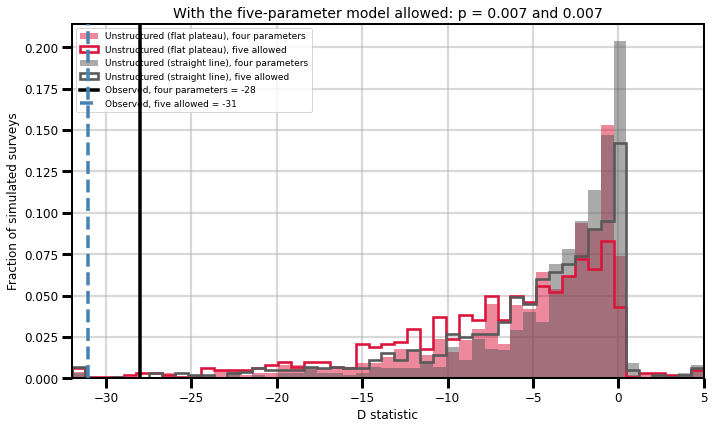

In [18]:
#### DOES ADDING THE FIVE-PARAMETER MODEL CHANGE THE D STATISTIC RESULT? ####
# The cell above showed the asymmetric model fits slightly better than the symmetric one,
# which means the observed D would move from -28.04 to -31.05 if it joined the structured
# family. That on its own proves nothing: giving the structured family a fifth parameter
# also lets the SIMULATED surveys chase noise better, so the null distribution shifts too.
# Only rerunning the simulation says which side moves further.
#
# Everything here is identical to the no-penalty cell except the model set, including the
# seed and the uniform residual resampling, so any difference is the extra model and
# nothing else.
#
# Degenerate asymmetric fits are refused rather than used. With five parameters a
# breakpoint can slide onto the edge of the temperature range, leaving a segment with
# almost no planets and a slope free to take any value; 6.5% of the bootstrap resamples in
# the cell above did exactly that. Those are optimiser failures, not better fits, so when
# one occurs the structured family falls back to its four-parameter members.

n_asym_simulations = 1000
n_asym_simulations_structured = 300
asym_rng = np.random.default_rng(11)
slope_bound = 5.0 / 1000
edge_margin = 100.0

for needed in ('asymmetric', 'fit_asymmetric'):
    if needed not in globals():
        raise RuntimeError(f'{needed} is missing -- run the asymmetric cell above first')


def asymmetric_loss_or_inf(sample_teff, sample_radius, sample_weights):
    # The five-parameter loss, or infinity if the fit ran off the end of the range
    loss, params = fit_asymmetric(sample_teff, sample_radius, sample_weights)
    if params is None or not np.isfinite(loss):
        return np.inf
    inside = (params[1] > x_min + edge_margin) and (params[1] < x_max - edge_margin) \
        and (params[2] > x_min + edge_margin) and (params[2] < x_max - edge_margin)
    steady = abs(params[3]) < slope_bound and abs(params[4]) < slope_bound
    return loss if (inside and steady) else np.inf


def d_statistic(fitted, extra_loss):
    # Four-parameter family, then the same with the five-parameter model allowed in
    best_simple = min(fitted[m]['loss'] for m in simple)
    four = min(fitted[m]['loss'] for m in structured)
    five = min(four, extra_loss)
    return (2 * n_planets * np.log(four / best_simple),
            2 * n_planets * np.log(five / best_simple))


observed_four, observed_five = d_statistic(ladder, asymmetric_loss)

signature = cache_signature('cell17_asym_d', n_asym_simulations,
                            n_asym_simulations_structured, n_planets, ladder_signature())
cached_result = load_cache('cell17_asym_d', signature)
if cached_result is None:
    asym_gaps = {}
    refused = {}
    for label in truths:
        name, params = truths[label]
        truth_curve = models[name]['func'](teff, *params)
        runs = n_asym_simulations if label in no_plateau else n_asym_simulations_structured
        four_values, five_values, dropped = [], [], 0
        for _ in range(runs):
            draw = asym_rng.integers(0, n_planets, size=n_planets)
            fake_radius = truth_curve + residual_pool[label][draw]
            fitted = fit_ladder(teff, fake_radius, weights)
            extra = asymmetric_loss_or_inf(teff, fake_radius, weights)
            if not np.isfinite(extra):
                dropped += 1
            four, five = d_statistic(fitted, extra)
            four_values.append(four)
            five_values.append(five)
        four_values, five_values = np.array(four_values), np.array(five_values)
        good = np.isfinite(four_values) & np.isfinite(five_values)
        asym_gaps[label] = (four_values[good], five_values[good])
        refused[label] = dropped / runs
    save_cache('cell17_asym_d', signature, (asym_gaps, refused))
else:
    asym_gaps, refused = cached_result

print("The D statistic with and without the five-parameter model in the structured family")
print("=" * 88)
print(f"  observed D, four-parameter family  {observed_four:+.2f}")
print(f"  observed D, five-parameter allowed {observed_five:+.2f}")
print(f"\n  asymmetric fits refused as degenerate, per truth:")
for label in truths:
    print(f"    {label:<22} {refused[label]:.1%}")

print(f"\n{'truth':<24}{'runs':>6}{'p (four param)':>17}{'p (five param)':>17}{'change':>10}")
print("-" * 88)
for label in truths:
    four_values, five_values = asym_gaps[label]
    p_four = np.mean(four_values <= observed_four)
    p_five = np.mean(five_values <= observed_five)
    print(f"{label:<24}{len(four_values):>6}{p_four:>17.4f}{p_five:>17.4f}"
          f"{p_five - p_four:>+10.4f}")

print("\nHow far the null distributions moved when the fifth parameter was allowed")
print("-" * 88)
for label in truths:
    four_values, five_values = asym_gaps[label]
    shift = five_values - four_values
    print(f"  {label:<22} median D {np.median(four_values):>+7.2f} -> "
          f"{np.median(five_values):>+7.2f}, median shift {np.median(shift):>+6.2f}, "
          f"5th percentile {np.percentile(four_values, 5):>+7.2f} -> "
          f"{np.percentile(five_values, 5):>+7.2f}")

print(f"\n  The observed statistic moved by {observed_five - observed_four:+.2f}.")
print(f"  The nulls moved by "
      f"{np.median(asym_gaps['flat plateau'][1] - asym_gaps['flat plateau'][0]):+.2f} and "
      f"{np.median(asym_gaps['straight line'][1] - asym_gaps['straight line'][0]):+.2f} at the median.")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

everything = np.concatenate([asym_gaps[l][k] for l in no_plateau for k in (0, 1)])
low, high = np.floor(np.percentile(everything, 0.5)), np.ceil(np.percentile(everything, 99.5))
edges = np.linspace(low, high, 50)
for label, color in (('flat plateau', 'crimson'), ('straight line', '0.35')):
    four_values, five_values = asym_gaps[label]
    ax.hist(np.clip(four_values, low, high), bins=edges, alpha=0.5, color=color,
            weights=np.full(len(four_values), 1 / len(four_values)),
            label=f'Unstructured ({label}), four parameters')
    ax.hist(np.clip(five_values, low, high), bins=edges, histtype='step', linewidth=2.6,
            color=color, weights=np.full(len(five_values), 1 / len(five_values)),
            label=f'Unstructured ({label}), five allowed')

ax.axvline(observed_four, color='black', linewidth=3.5, zorder=6,
           label=f'Observed, four parameters = {observed_four:.0f}')
ax.axvline(observed_five, color='steelblue', linewidth=3.5, linestyle='--', zorder=6,
           label=f'Observed, five allowed = {observed_five:.0f}')

p_flat = np.mean(asym_gaps['flat plateau'][1] <= observed_five)
p_line = np.mean(asym_gaps['straight line'][1] <= observed_five)
ax.set_xlabel('D statistic', size=12)
ax.set_ylabel('Fraction of simulated surveys', size=12)
ax.set_xlim(low, high)
ax.set_title(f'With the five-parameter model allowed: p = {p_flat:.3f} and {p_line:.3f}', size=14)
ax.legend(loc='upper left', fontsize=9)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_asymmetric_d.png', dpi=300, bbox_inches='tight')

In [19]:
#### HOW STABLE ARE THESE COUNTS BETWEEN INDEPENDENT RUNS? ####
# Every p-value quoted above is a count out of 1000, and counts that small carry real
# sampling error: 7 out of 1000 has a 95% interval running from about 0.003 to 0.014.
# Before any of these numbers go in a table it is worth knowing how much they move when
# the simulation is simply run again.
#
# Two fresh seeds are run here and compared with the one already computed above. Nothing
# about the method changes between them -- same generation, same statistic, same counts --
# so any spread is pure Monte Carlo noise and sets the precision the numbers can be
# quoted to.

n_stability_simulations = 1000
stability_seeds = [12, 13]

for needed in ('forward_d', 'observed_d', 'build_draw_probabilities', 'weights_for'):
    if needed not in globals():
        raise RuntimeError(f'{needed} is missing -- run the cells above first')

signature = cache_signature('cell18_stability', n_stability_simulations,
                            tuple(stability_seeds), n_planets, ladder_signature())
cached_result = load_cache('cell18_stability', signature)
if cached_result is None:
    repeats = {}
    for seed in stability_seeds:
        stability_rng = np.random.default_rng(seed)
        for label in truths:
            name, params = truths[label]
            truth_curve = models[name]['func'](teff, *params)
            residual_pool_here = residual_pool[label]
            cumulative = build_draw_probabilities(truth_curve)
            values = []
            for _ in range(n_stability_simulations):
                u = stability_rng.random(n_planets)
                picked = (cumulative < u[:, None]).sum(axis=1).clip(0, n_planets - 1)
                fake_radius = truth_curve + residual_pool_here[picked]
                fake_weights = weights_for(fake_radius)
                values.append(likelihood_ratio_here(fit_ladder(teff, fake_radius, fake_weights)))
            values = np.array(values)
            repeats[(seed, label)] = values[np.isfinite(values)]
    save_cache('cell18_stability', signature, repeats)
else:
    repeats = cached_result

print(f"Surveys reaching the observed D of {observed_d:+.2f}, three independent runs")
print("=" * 84)
print(f"{'true underlying model':<24}{'seed 11':>12}{'seed 12':>12}{'seed 13':>12}"
      f"{'pooled':>14}{'pooled p':>10}")
print("-" * 84)
for label in truths:
    counts, total_reached, total_runs = [], 0, 0
    for values in [forward_d[label]] + [repeats[(seed, label)] for seed in stability_seeds]:
        values = values[np.isfinite(values)]
        reached = int(np.sum(values <= observed_d))
        counts.append(f"{reached}/{len(values)}")
        total_reached += reached
        total_runs += len(values)
    print(f"  {label:<22}" + "".join(f"{c:>12}" for c in counts)
          + f"{f'{total_reached}/{total_runs}':>14}{total_reached / total_runs:>10.4f}")

# The spread across runs, against what the binomial alone predicts
print("\nRun-to-run spread against the sampling error expected from the counts")
print("-" * 84)
for label in truths:
    reached = []
    for values in [forward_d[label]] + [repeats[(seed, label)] for seed in stability_seeds]:
        values = values[np.isfinite(values)]
        reached.append(int(np.sum(values <= observed_d)))
    mean_count = np.mean(reached)
    print(f"  {label:<22} counts {str(reached):<18} spread {np.std(reached, ddof=1):>6.1f}, "
          f"binomial expects about {np.sqrt(mean_count):.1f}")

  loaded cell18_stability from cache, computed 2026-10-19 16:13
Surveys reaching the observed D of -28.04, three independent runs
true underlying model        seed 11     seed 12     seed 13        pooled  pooled p
------------------------------------------------------------------------------------
  one sloping section        43/1000     47/1000     46/1000      136/3000    0.0453
  two sloping sections      108/1000    103/1000    111/1000      322/3000    0.1073
  flat plateau                7/1000      5/1000      5/1000       17/3000    0.0057
  straight line               2/1000      2/1000      1/1000        5/3000    0.0017

Run-to-run spread against the sampling error expected from the counts
------------------------------------------------------------------------------------
  one sloping section    counts [43, 47, 46]       spread    2.1, binomial expects about 6.7
  two sloping sections   counts [108, 103, 111]    spread    4.0, binomial expects about 10.4
  flat plateau   